# Credit Card Fraud Detection: Predictive & Prescriptive Pipeline

**Goal:** detect fraudulent credit card transactions while keeping
customer satisfaction in mind, catching fraud without needlessly
blocking legitimate transactions.

**Dataset:** a simulated credit card transaction log (1,296,675 rows),
cleaned through a Tableau Prep flow (duplicate/null handling, `age` derived
from date of birth). ~0.58% of transactions are labeled fraudulent.

**How this notebook reads:** each section opens with why that step exists
before showing the code for it. Three models are trained (a neural network,
Random Forest, and XGBoost), compared with statistical tests rather than
eyeballed metric differences, then combined into a routing pipeline whose
design comes from the error-analysis sections earlier in the notebook.

This keeps the work that made it into the final pipeline. A few things were
tried and dropped along the way (a feature-ablation test, a different
activation function, some hyperparameter searches) and aren't reproduced
here.

## 0. Imports & Reproducibility

Every library used in this notebook, imported once up front. The seed
block matters more than it looks: `random_state` parameters on individual
sklearn/XGBoost calls only cover those specific calls. The ANN's weight
initialization, Dropout, and batch shuffling are separate sources of
randomness that need to be seeded here, once, or every re-run of this
notebook trains a measurably different network.

In [1]:
import logging
import os
import random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder, LabelEncoder
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    classification_report, confusion_matrix, roc_auc_score, roc_curve,
    precision_recall_curve, precision_score, recall_score, f1_score,
)
from xgboost import XGBClassifier

from keras.models import Sequential
from keras.layers import Dense, Dropout, BatchNormalization, Input
from keras.optimizers import Adam
from keras.callbacks import EarlyStopping, ReduceLROnPlateau

from scipy.stats import mannwhitneyu
from statsmodels.stats.contingency_tables import mcnemar, cochrans_q

# Reproducibility. sklearn/XGBoost's `random_state` params below only cover
# those libraries -- the ANN's Dropout, weight init, and batch shuffling are
# separate sources of randomness that must be seeded here or every re-run
# trains a slightly different network.
SEED = 42
os.environ["PYTHONHASHSEED"] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

sns.set_style("whitegrid")
pd.set_option("display.max_columns", 30)

logging.getLogger("matplotlib.font_manager").setLevel(logging.ERROR)

## 1. Data Loading & Integrity Check

Before anything else, confirm the data is clean (no duplicates, no nulls)
and check the baseline fraud rate the whole project is built around.
`output.csv` comes from a Tableau Prep cleaning flow that already handled
column removal, null/duplicate handling, and deriving `age` from date of
birth.

In [2]:
df = pd.read_csv("output.csv")
print(f"Shape: {df.shape}")
print(f"Duplicate rows: {df.duplicated().sum()}")
print(f"Total null values: {df.isnull().sum().sum()}")
print(f"Fraud rate: {df['is_fraud'].mean():.4%}  ({df['is_fraud'].sum():,} of {len(df):,})")

df.head(3)

Shape: (1296675, 20)
Duplicate rows: 0
Total null values: 0
Fraud rate: 0.5789%  (7,506 of 1,296,675)


,trans_date_trans_time,cc_num,merchant,category,amt,gender,street,city,state,zip,lat,long,city_pop,job,dob,age,trans_num,merch_lat,merch_long,is_fraud
0,5/8/2020 6:43:53 AM,213161293389774,"Schoen, Kuphal and Nitzsche",grocery_pos,48.31,F,74890 Rodriguez Springs Apt. 540,West Henrietta,NY,14586,43.0397,-77.6871,10256,"Teacher, primary school",6/24/1968,57,e1ab00d4df7634a8f97953a0a9d15884,43.011995,-76.873188,0
1,5/8/2020 6:45:17 AM,4390966588600992777,"Bernhard, Grant and Langworth",shopping_pos,3.05,M,8149 Harris Divide,Oklahoma City,OK,73134,35.6174,-97.5583,640470,Advertising copywriter,6/24/1966,59,d75cc83afc318cddc090f65fca27e6b9,35.560018,-97.755214,0
2,5/8/2020 6:45:34 AM,6011652924285713,"Mosciski, Gislason and Mertz",grocery_pos,93.80,F,19838 Tonya Prairie Apt. 947,Rocky Mount,MO,65072,38.2911,-92.7059,1847,Tax inspector,10/26/1988,37,cfb267505e806ca67072613409405b26,38.460584,-93.643066,0


**Why this matters going forward:** a 0.58% fraud rate means a model that
predicts "not fraud" for every single transaction would already be
99.4% accurate and completely useless. Accuracy isn't a meaningful metric for this problem;
every evaluation from here on focuses on precision, recall, and F1 for the
*fraud* class, plus AUC-ROC as a threshold-free summary.

## 2. Data Cleaning

Drop personally-identifiable and redundant columns before feature
engineering: `street`/`city`/`state`/`zip` are already captured more
usefully by `lat`/`long`, `trans_num` is a unique ID with no predictive
value, `city_pop` and `job` weren't validated as informative during
descriptive analysis, and `dob` is redundant with the already-derived `age`.
Calendar features (`month`, `hour`, `week`) are extracted from the
transaction timestamp here since several behavioral features below depend
on them.

In [3]:
drop_cols = ["street", "city", "state", "zip", "trans_num", "city_pop", "job", "dob"]
df = df.drop(columns=drop_cols)

df["trans_date_trans_time"] = pd.to_datetime(df["trans_date_trans_time"])
df["month"] = df["trans_date_trans_time"].dt.month
df["hour"] = df["trans_date_trans_time"].dt.hour
df["week"] = df["trans_date_trans_time"].dt.dayofweek

## 3. Geographic Distance Feature (ECEF)

A naive `lat`/`long` subtraction treats the Earth as flat, which matters
here: one degree of longitude covers ~111km at the equator but only
~55-80km near the poles, so a flat subtraction would bias the distance
feature by region. Converting both the customer's and the merchant's
coordinates to Earth-Centered, Earth-Fixed (ECEF) 3D Cartesian coordinates
and taking standard Euclidean distance between them is geometrically
accurate everywhere on the globe, at the cost of a few extra lines of
trigonometry. The same conversion is reused later for `implied_speed_kmh`.

In [4]:
EARTH_RADIUS_KM = 6371


def latlon_to_ecef(lat, lon):
    """Convert geographic coordinates to ECEF 3D Cartesian coordinates (km)."""
    lat_r, lon_r = np.radians(lat), np.radians(lon)
    x = EARTH_RADIUS_KM * np.cos(lat_r) * np.cos(lon_r)
    y = EARTH_RADIUS_KM * np.cos(lat_r) * np.sin(lon_r)
    z = EARTH_RADIUS_KM * np.sin(lat_r)
    return x, y, z


cust_x, cust_y, cust_z = latlon_to_ecef(df["lat"], df["long"])
merch_x, merch_y, merch_z = latlon_to_ecef(df["merch_lat"], df["merch_long"])

df["distance"] = np.sqrt(
    (cust_x - merch_x) ** 2 + (cust_y - merch_y) ** 2 + (cust_z - merch_z) ** 2
)

## 4. Feature Engineering

Every feature below comes from a specific hypothesis about how fraud looks
different from normal spending. Two of them (`prior_fraud_count`,
`implied_speed_kmh`) need a **leak-safe** construction, explained where
they're built.

**Why leak-safety matters:** it would be trivial to build a feature like
"has this card ever been defrauded" with a plain
`groupby().transform("sum")` over the whole dataset, but that includes the
*current row's own label* in its own feature. The model would learn to
exploit that as a shortcut instead of a real fraud signal, and no real
fraud-detection system could compute it at the moment a transaction
happens, since you don't know yet whether *this* transaction is fraud
(that's the whole question). Every time-dependent feature here is computed
on a time-sorted view of the data and only looks *strictly before* the
current transaction.

**`is_night` window:** rather than a plain midnight-anchored block, this
flag comes from the descriptive (Tableau) hourly fraud-rate chart, which
showed fraud peaking at 21:00-23:00 and staying elevated through
00:00-03:00 before dropping back to baseline at 04:00. The window is set
to 21:00-03:59 to match that.

In [5]:
df["category"] = df["category"].astype("category")
df["gender"] = df["gender"].astype("category")

# Night flag: peak 21:00-23:00, still elevated through 00:00-03:00, drops at 04:00
df["is_night"] = ((df["hour"] >= 21) | (df["hour"] < 4)).astype(int)

# Single time-sorted view, reused by every leak-safe feature below.
df_time_sorted = df.sort_values(["cc_num", "trans_date_trans_time"])

# Rolling 150-day average spend per card, strictly before the current
# transaction. A plain groupby().transform("mean") would use every
# transaction that card ever makes, including ones that happen after the
# row being scored, information a live system would never have at decision
# time. 150 days comes from the data: it spans 537 days total, and most
# cards stay active across nearly the whole range, so 150 days covers
# about 28% of a typical card's history, long enough for a stable average,
# short enough to track real drift in spending habits.
_time_indexed = df_time_sorted.set_index("trans_date_trans_time")
_rolling_sum = _time_indexed.groupby("cc_num")["amt"].rolling("150D").sum()
_rolling_count = _time_indexed.groupby("cc_num")["amt"].rolling("150D").count()
_rolling_sum = _rolling_sum.reset_index(level=0, drop=True)
_rolling_count = _rolling_count.reset_index(level=0, drop=True)
_rolling_sum.index = df_time_sorted.index
_rolling_count.index = df_time_sorted.index

_prior_150d_sum = _rolling_sum - df_time_sorted["amt"]
_prior_150d_count = _rolling_count - 1
_global_mean_amt = df["amt"].mean()
_avg_amt_150d = (_prior_150d_sum / _prior_150d_count.replace(0, np.nan)).fillna(_global_mean_amt)

df.loc[df_time_sorted.index, "avg_amt_per_card"] = _avg_amt_150d
df["amt_ratio"] = df["amt"] / (df["avg_amt_per_card"] + 1e-5)
df["amt_deviation"] = df["amt"] - df["avg_amt_per_card"]

# Prior transaction count, same reasoning: how many transactions this card
# (or merchant) has seen strictly before this one, not a lifetime total
# that doesn't vary row to row.
df.loc[df_time_sorted.index, "tx_count_per_card"] = df_time_sorted.groupby("cc_num").cumcount()

df_merch_sorted = df.sort_values(["merchant", "trans_date_trans_time"])
df.loc[df_merch_sorted.index, "merch_tx_count"] = df_merch_sorted.groupby("merchant").cumcount()

print(f"avg_amt_per_card (150-day trailing) -- mean: {df['avg_amt_per_card'].mean():.2f}, "
      f"median: {df['avg_amt_per_card'].median():.2f}")

avg_amt_per_card (150-day trailing) -- mean: 70.27, median: 64.86


**`avg_amt_per_card` / `amt_ratio` / `amt_deviation`:** a fraudulent
charge often looks unusual relative to that specific card's own spending
habits, not relative to some global average: a `$400` charge is unremarkable
for a card that normally spends `$350`, and very unusual for a card that
normally spends `$20`. `amt_ratio` and `amt_deviation` capture that per-card
deviation directly instead of leaving every model to re-derive it from raw
`amt` and `cc_num`.

The average itself is computed over a rolling 150-day window, strictly
before each transaction, not the card's whole history. Using the full
history (including transactions that happen after the one being scored)
would hand the model information no live system actually has at decision
time, and would let a card's future, more established spending pattern
quietly stabilize what "normal" looks like for an early transaction on
that card. The 150-day window fixes that while still using enough history
for a stable estimate.

**`tx_count_per_card` / `merch_tx_count`:** how many transactions this
card or merchant has seen *before* this one, not a lifetime total. Same
leak-safety reasoning, and it has a side benefit: a lifetime total is the
same number on every row for a given card, so it can't distinguish an
early transaction from a late one. A prior-count does, and reads more
naturally as "how established does this account look right now."

### Why `prior_fraud_count`

Card-level analysis on this dataset found that 77.5% of cards get
defrauded at least once, and a compromised card averages ~10 fraud
transactions, not 1: a repeat-victimization pattern, not a one-off event.
`prior_fraud_count` captures that directly: how many times *this* card was
confirmed fraudulent strictly before the current transaction. Left as an
unbounded count rather than a rolling window, a card that was compromised
once staying flagged long-term is the intended behavior, not something
that should fade out after a few months the way a spending-average should.

**Two caveats, and the second one matters more.**

With only 983 unique cards in this simulated dataset, every card
accumulates substantial history fast, so this feature likely looks
stronger here than it would on a larger, real card population where many
cards are genuinely new with no history either way.

The bigger one: this feature is leak-safe in time order, but it still
assumes something a live system does not have. It assumes a past
transaction is already *confirmed* fraudulent by the time the next one
gets scored. In production that confirmation arrives when the cardholder
disputes the charge, days or weeks later, so a deployed version of this
count would lag by the chargeback window and read lower than the value
computed here. `prior_fraud_count` turns out to be a top-three feature for
all three models, so that gap is worth stating up front rather than
leaving to a limitations list at the end.

In [6]:
# Prior fraud count: how many times THIS card was confirmed fraudulent
# strictly before the current transaction. Reuses df_time_sorted from
# above (already sorted by card and timestamp) rather than sorting again.
df.loc[df_time_sorted.index, "prior_fraud_count"] = (
    df_time_sorted.groupby("cc_num")["is_fraud"].cumsum() - df_time_sorted["is_fraud"]
)

print(f"prior_fraud_count -- mean: {df['prior_fraud_count'].mean():.3f}, "
      f"max: {df['prior_fraud_count'].max():.0f}, "
      f"nonzero: {(df['prior_fraud_count'] > 0).mean():.2%} of rows")

prior_fraud_count -- mean: 3.899, max: 19, nonzero: 39.55% of rows


### Why `implied_speed_kmh`

The "impossible travel" check: a card cloned or stolen and used in two
distant locations within a short time window produces a physically
implausible implied speed, since no legitimate cardholder teleports. For
example, if a customer swipes their card in one city and then, an hour
later, again 500km away, that is not something a person can do by car,
only by plane, so a gap like that is a real warning sign, not a
coincidence of timing. This feature computes the distance from the
*previous* transaction's merchant location (same ECEF method as above)
divided by the time elapsed since that transaction, using the same
leak-safe time-sorted pattern as `prior_fraud_count`.

Checked against the full dataset before being added as a model feature:
fraud shows a median implied speed of 64.3 km/h vs. 19.9 km/h for
legitimate transactions (3.2x), is 2.8x more likely to exceed 130 km/h
(faster than normal driving), and 4.1x more likely to exceed 900 km/h
(faster than a commercial flight, essentially impossible for a legitimate
cardholder). That gap is what justifies the feature, not just the
intuition that it should help.

Two numerical details:
- **Divide-by-zero guard:** two transactions on the same card at (near)
  the same timestamp would otherwise divide by ~zero hours, producing
  `inf`. The time gap is floored at 6 seconds, so a near-simultaneous
  transaction still produces a very large but finite speed, since the tiny
  time gap is itself the signal.
- **First transaction per card:** has no previous transaction to compare
  to, so it's filled with 0 (no anomaly signal available) rather than left
  as `NaN`, which would break model training.

In [7]:
# Implied travel speed since the previous transaction on the same card.
prev_time = df_time_sorted.groupby("cc_num")["trans_date_trans_time"].shift(1)
prev_lat = df_time_sorted.groupby("cc_num")["merch_lat"].shift(1)
prev_long = df_time_sorted.groupby("cc_num")["merch_long"].shift(1)

time_since_prev_hours = (
    (df_time_sorted["trans_date_trans_time"] - prev_time).dt.total_seconds() / 3600
)
prev_x, prev_y, prev_z = latlon_to_ecef(prev_lat, prev_long)
curr_x, curr_y, curr_z = latlon_to_ecef(df_time_sorted["merch_lat"], df_time_sorted["merch_long"])
distance_from_prev_km = np.sqrt(
    (curr_x - prev_x) ** 2 + (curr_y - prev_y) ** 2 + (curr_z - prev_z) ** 2
)

# Floor at 6 seconds so a near-simultaneous transaction produces a very large
# but finite speed instead of inf.
safe_hours = time_since_prev_hours.clip(lower=6 / 3600)
implied_speed = distance_from_prev_km / safe_hours

df.loc[df_time_sorted.index, "implied_speed_kmh"] = implied_speed
df["implied_speed_kmh"] = df["implied_speed_kmh"].fillna(0)

print(f"implied_speed_kmh -- mean: {df['implied_speed_kmh'].mean():.2f}, "
      f"median: {df['implied_speed_kmh'].median():.2f}, "
      f"max: {df['implied_speed_kmh'].max():.0f}")

implied_speed_kmh -- mean: 161.31, median: 19.99, max: 143127


### Final feature set and chronological train/test split

Categorical columns are encoded two ways in parallel: one-hot for the ANN
(which has no native way to handle categories) and label-encoded for the
tree models (which split on raw values fine and don't need the extra
dimensionality one-hot encoding adds). Both encodings come from the same
underlying columns so all three models see equivalent information.

The split itself is chronological, not a random stratified split: the
earlier ~80% of transactions by date become the training set, the later
~20% become the test set. A random split has a subtle problem even with
every feature computed leak-safely: it can still let training rows sit
chronologically after test rows, so the model's fit could implicitly pick
up on later time-period patterns a real deployment wouldn't have yet when
scoring an earlier test transaction. A chronological split evaluates the
model the way it would actually be used, trained on history, applied to
what comes after. Stratification isn't possible across a real time
boundary, so the resulting fraud rates are checked and printed instead of
assumed to match.

In [8]:
le_category = LabelEncoder()
le_gender = LabelEncoder()
df["category_enc"] = le_category.fit_transform(df["category"])
df["gender_enc"] = le_gender.fit_transform(df["gender"])

num_cols = [
    "amt", "age", "distance", "hour", "week", "month", "is_night",
    "merch_lat", "merch_long", "avg_amt_per_card", "amt_ratio",
    "amt_deviation", "tx_count_per_card", "merch_tx_count", "prior_fraud_count",
    "implied_speed_kmh",
]
cat_cols = ["gender", "category"]           # one-hot encoded, for the ANN
enc_cols = ["category_enc", "gender_enc"]   # label encoded, for RF / XGBoost

ann_features = num_cols + cat_cols
tree_features = num_cols + enc_cols

X = df[ann_features]
y = df["is_fraud"]

split_cutoff = df["trans_date_trans_time"].quantile(0.80)
train_mask = df["trans_date_trans_time"] <= split_cutoff
test_mask = ~train_mask

X_train, X_test = X[train_mask], X[test_mask]
y_train, y_test = y[train_mask], y[test_mask]

# Tree models reuse the exact same row split, just with label-encoded categoricals
tree_X_train = df.loc[X_train.index, tree_features]
tree_X_test = df.loc[X_test.index, tree_features]

print(f"Split cutoff: {split_cutoff}")
print(f"Train: {X_train.shape[0]:,} rows | Test: {X_test.shape[0]:,} rows")
print(f"Train fraud rate: {y_train.mean():.4%} | Test fraud rate: {y_test.mean():.4%}")
test_amt = df.loc[X_test.index, "amt"].values  # dollar amount per test row, same order as y_test/X_test

Split cutoff: 2020-03-06 07:15:34.200000
Train: 1,037,340 rows | Test: 259,335 rows
Train fraud rate: 0.5753% | Test fraud rate: 0.5931%


## 5. Shared Evaluation & Plotting Utilities

The three models below are trained separately but evaluated through one
shared function each, not three copy-pasted evaluation blocks. That keeps
the comparison between them fair: same metrics, same plot types, same
threshold-sweep method, instead of three slightly different ad hoc
evaluations that happen to look comparable.

In [9]:
def evaluate_model(name, y_true, y_pred, y_proba, threshold):
    """Print a classification report + confusion-matrix breakdown and
    return the metrics as a dict, so every downstream comparison chart reads
    real computed numbers instead of hand-typed literals."""
    print("=" * 60)
    print(f"{name}  CLASSIFICATION REPORT (threshold={threshold})")
    print("=" * 60)
    print(classification_report(y_true, y_pred, target_names=["Not Fraud", "Fraud"]))

    auc = roc_auc_score(y_true, y_proba)
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    print(f"AUC-ROC: {auc:.4f}")
    print(f"True Negatives  (correctly allowed): {tn}")
    print(f"False Positives (wrongly blocked):   {fp}")
    print(f"False Negatives (missed fraud):      {fn}  <- most costly")
    print(f"True Positives  (caught fraud):      {tp}")

    return {
        "name": name, "threshold": threshold,
        "precision": precision_score(y_true, y_pred),
        "recall": recall_score(y_true, y_pred),
        "f1": f1_score(y_true, y_pred),
        "auc": auc, "tn": tn, "fp": fp, "fn": fn, "tp": tp,
        "fpr": None, "tpr": None,  # filled in by plot_diagnostics
    }


def fn_dollar_sum(y_true, y_pred, amt):
    """Total dollar amount of the missed-fraud (false-negative) transactions
    for one prediction array. The same $ figure gets threaded through every
    comparison table below, so a model, ensemble, or threshold choice is
    judged by real dollars at risk, not just a missed-fraud count."""
    y_arr = np.asarray(y_true)
    pred_arr = np.asarray(y_pred)
    amt_arr = np.asarray(amt)
    return float(amt_arr[(y_arr == 1) & (pred_arr == 0)].sum())

In [10]:
def plot_diagnostics(name, y_true, y_proba, threshold, color, metrics, save_prefix=None):
    """Confusion matrix, ROC curve, PR curve, threshold sweep, and
    probability histogram for one model."""
    y_pred = (y_proba >= threshold).astype(int)
    cm = confusion_matrix(y_true, y_pred)

    fig, ax = plt.subplots(figsize=(5, 4))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=ax,
                xticklabels=["Not Fraud", "Fraud"], yticklabels=["Not Fraud", "Fraud"])
    ax.set_title(f"{name} Confusion Matrix (threshold={threshold})")
    ax.set_ylabel("Actual")
    ax.set_xlabel("Predicted")
    plt.tight_layout()
    if save_prefix:
        plt.savefig(f"output/{save_prefix}_confusion_matrix.png", dpi=150, bbox_inches="tight")
    plt.show()

    fpr, tpr, _ = roc_curve(y_true, y_proba)
    metrics["fpr"], metrics["tpr"] = fpr, tpr
    plt.figure(figsize=(6, 5))
    plt.plot(fpr, tpr, color=color, lw=2, label=f"{name} ROC (AUC={metrics['auc']:.4f})")
    plt.plot([0, 1], [0, 1], "k--", label="Random Guess")
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.title(f"{name} ROC Curve")
    plt.legend(loc="lower right")
    plt.tight_layout()
    if save_prefix:
        plt.savefig(f"output/{save_prefix}_roc_curve.png", dpi=150, bbox_inches="tight")
    plt.show()

    prec, rec, _ = precision_recall_curve(y_true, y_proba)
    plt.figure(figsize=(6, 5))
    plt.plot(rec, prec, color=color, lw=2)
    plt.xlabel("Recall")
    plt.ylabel("Precision")
    plt.title(f"{name} Precision-Recall Curve")
    plt.tight_layout()
    if save_prefix:
        plt.savefig(f"output/{save_prefix}_pr_curve.png", dpi=150, bbox_inches="tight")
    plt.show()

    thresh_range = np.arange(0.05, 0.95, 0.05)
    rec_list = [recall_score(y_true, (y_proba >= t).astype(int)) for t in thresh_range]
    prec_list = [precision_score(y_true, (y_proba >= t).astype(int)) for t in thresh_range]
    f1_list = [f1_score(y_true, (y_proba >= t).astype(int)) for t in thresh_range]

    plt.figure(figsize=(9, 5))
    plt.plot(thresh_range, rec_list, label="Recall", marker="o")
    plt.plot(thresh_range, prec_list, label="Precision", marker="s")
    plt.plot(thresh_range, f1_list, label="F1 Score", marker="^")
    plt.axvline(x=threshold, color="gray", linestyle="--", label=f"Chosen ({threshold})")
    plt.title(f"{name} Threshold vs Recall / Precision / F1")
    plt.xlabel("Threshold")
    plt.ylabel("Score")
    plt.legend()
    plt.tight_layout()
    if save_prefix:
        plt.savefig(f"output/{save_prefix}_threshold_sweep.png", dpi=150, bbox_inches="tight")
    plt.show()

    plt.figure(figsize=(9, 5))
    plt.hist(y_proba[y_true == 0], bins=50, alpha=0.6, label="Not Fraud", color="steelblue")
    plt.hist(y_proba[y_true == 1], bins=50, alpha=0.6, label="Fraud", color="red")
    plt.axvline(x=threshold, color="black", linestyle="--", label=f"Threshold ({threshold})")
    plt.title(f"{name} Predicted Fraud Probability Distribution")
    plt.xlabel("Predicted Probability")
    plt.ylabel("Count")
    plt.yscale("log")
    plt.legend()
    plt.tight_layout()
    if save_prefix:
        plt.savefig(f"output/{save_prefix}_prob_dist.png", dpi=150, bbox_inches="tight")
    plt.show()


def plot_feature_importance(name, importance_df, palette, top_n=10, save_prefix=None):
    top = importance_df.head(top_n)
    plt.figure(figsize=(9, 7))
    sns.barplot(x="Importance", y="Feature", data=top, hue="Feature",
                palette=palette, legend=False)
    plt.title(f"{name} Feature Importance")
    plt.tight_layout()
    if save_prefix:
        plt.savefig(f"output/{save_prefix}_feature_importance.png", dpi=150, bbox_inches="tight")
    plt.show()
    print(f"\n{name} Top {top_n} Features:")
    print(top.to_string(index=False))

## 6. Model 1: Artificial Neural Network (ANN)

**Architecture choices:**
- **`StandardScaler` + one-hot encoding:** neural networks train on
  gradient descent, which is sensitive to feature scale; an unscaled `amt`
  column ranging into the thousands would dominate the gradient over a
  0/1 `is_night` flag purely due to magnitude, not importance.
- **`BatchNormalization` after each hidden layer:** keeps activations in a
  stable range during training, which also counters a specific risk of the
  `ReLU` activation used here. A "dead" neuron whose input lands
  permanently negative outputs zero forever and stops learning;
  batch-normalizing the layer's output before the next one reduces how
  often that happens.
- **`Dropout` (0.3, 0.3, 0.2):** randomly zeroes a fraction of neurons each
  training step, which stops the network from memorizing specific training
  examples instead of learning general patterns. Dropout is lower in the
  last hidden layer (0.2 vs 0.3) to leave more capacity intact right
  before the final decision.
- **Class weighting, not SMOTE:** with fraud at ~0.58%, the model needs to
  be told that misclassifying a fraud case costs more than misclassifying
  a legitimate one. `class_weight` does this directly during training
  without synthesizing artificial minority-class examples the way SMOTE
  does, which is simpler and avoids the risk of synthetic examples that
  don't reflect real fraud patterns.
- **`EarlyStopping` + `ReduceLROnPlateau`:** trains for up to 50 epochs but
  stops automatically once validation loss stops improving for 5 epochs
  (restoring the best weights, not the last ones), and halves the learning
  rate if progress stalls for 3 epochs first. The epoch count is a
  ceiling, not a target the network has to fill.

In [11]:
ANN_THRESHOLD = 0.80
ANN_CLASS_WEIGHT = {0: 1, 1: 5}

ann_transformer = ColumnTransformer([
    ("num", StandardScaler(), num_cols),
    ("cat", OneHotEncoder(sparse_output=False, handle_unknown="ignore", drop="first"), cat_cols),
])
ann_X_train = ann_transformer.fit_transform(X_train)
ann_X_test = ann_transformer.transform(X_test)

ann_feature_names = num_cols + list(
    ann_transformer.named_transformers_["cat"].get_feature_names_out(cat_cols)
)

ann = Sequential([
    Input(shape=(ann_X_train.shape[1],)),
    Dense(128, activation="relu"), BatchNormalization(), Dropout(0.3),
    Dense(64, activation="relu"), BatchNormalization(), Dropout(0.3),
    Dense(32, activation="relu"), Dropout(0.2),
    Dense(1, activation="sigmoid"),
])
ann.compile(optimizer=Adam(learning_rate=0.001), loss="binary_crossentropy", metrics=["accuracy"])

ann_history = ann.fit(
    ann_X_train, y_train,
    epochs=50, batch_size=256,
    class_weight=ANN_CLASS_WEIGHT,
    validation_split=0.1,
    callbacks=[
        EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True),
        ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3, min_lr=1e-6),
    ],
    verbose=1,
)

ann_proba = ann.predict(ann_X_test, verbose=0).flatten()
ann_pred = (ann_proba >= ANN_THRESHOLD).astype(int)

Epoch 1/50
3647/3647 ━━━━━━━━━━━━━━━━━━━━ 16s 4ms/step - accuracy: 0.9894 - loss: 0.0649 - val_accuracy: 0.9962 - val_loss: 0.0123 - learning_rate: 0.0010
Epoch 2/50
3647/3647 ━━━━━━━━━━━━━━━━━━━━ 21s 4ms/step - accuracy: 0.9958 - loss: 0.0313 - val_accuracy: 0.9968 - val_loss: 0.0094 - learning_rate: 0.0010
Epoch 3/50
3647/3647 ━━━━━━━━━━━━━━━━━━━━ 11s 3ms/step - accuracy: 0.9967 - loss: 0.0240 - val_accuracy: 0.9977 - val_loss: 0.0072 - learning_rate: 0.0010
Epoch 4/50
3647/3647 ━━━━━━━━━━━━━━━━━━━━ 25s 4ms/step - accuracy: 0.9969 - loss: 0.0214 - val_accuracy: 0.9972 - val_loss: 0.0076 - learning_rate: 0.0010
Epoch 5/50
3647/3647 ━━━━━━━━━━━━━━━━━━━━ 13s 3ms/step - accuracy: 0.9974 - loss: 0.0188 - val_accuracy: 0.9975 - val_loss: 0.0069 - learning_rate: 0.0010
Epoch 6/50
3647/3647 ━━━━━━━━━━━━━━━━━━━━ 12s 3ms/step - accuracy: 0.9975 - loss: 0.0176 - val_accuracy: 0.9982 - val_loss: 0.0059 - learning_rate: 0.0010
Epoch 7/50
3647/3647 ━━━━━━━━━━━━━━━━━━━━ 12s 3ms/step - accuracy: 0.9

ANN  CLASSIFICATION REPORT (threshold=0.8)
              precision    recall  f1-score   support

   Not Fraud       1.00      1.00      1.00    257797
       Fraud       0.95      0.85      0.90      1538

    accuracy                           1.00    259335
   macro avg       0.97      0.93      0.95    259335
weighted avg       1.00      1.00      1.00    259335

AUC-ROC: 0.9987
True Negatives  (correctly allowed): 257722
False Positives (wrongly blocked):   75
False Negatives (missed fraud):      224  <- most costly
True Positives  (caught fraud):      1314


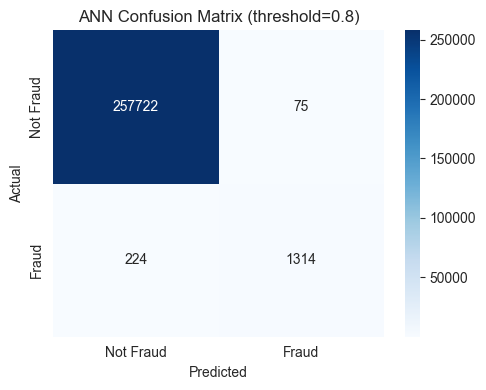

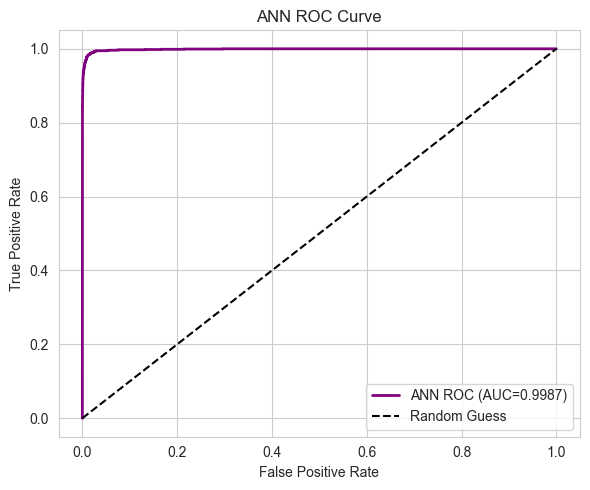

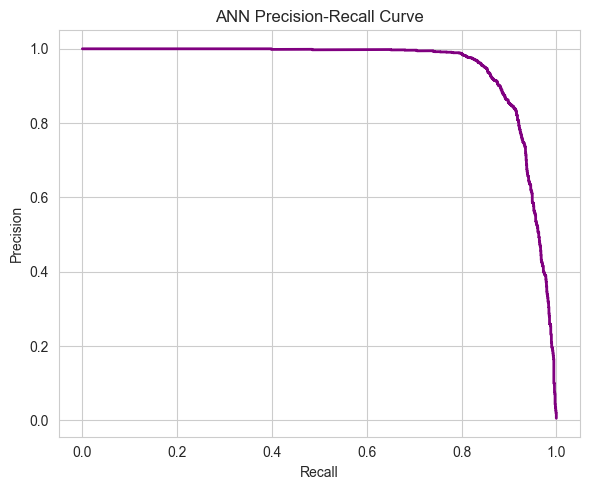

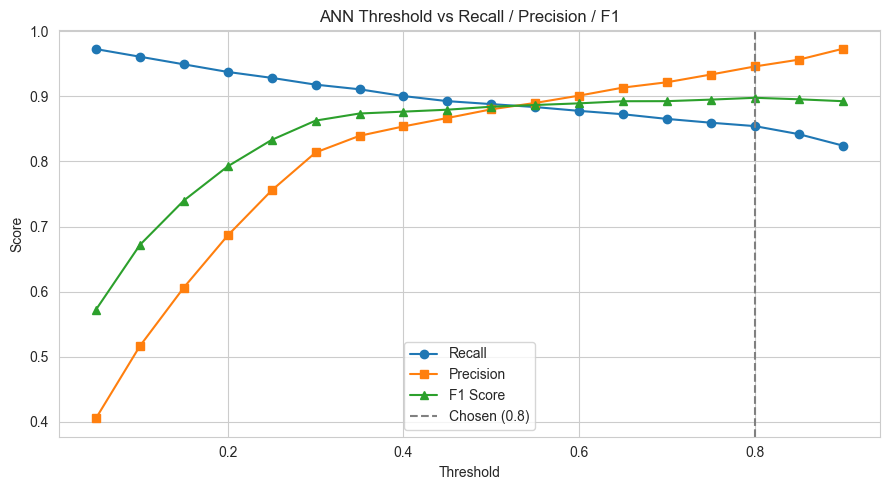

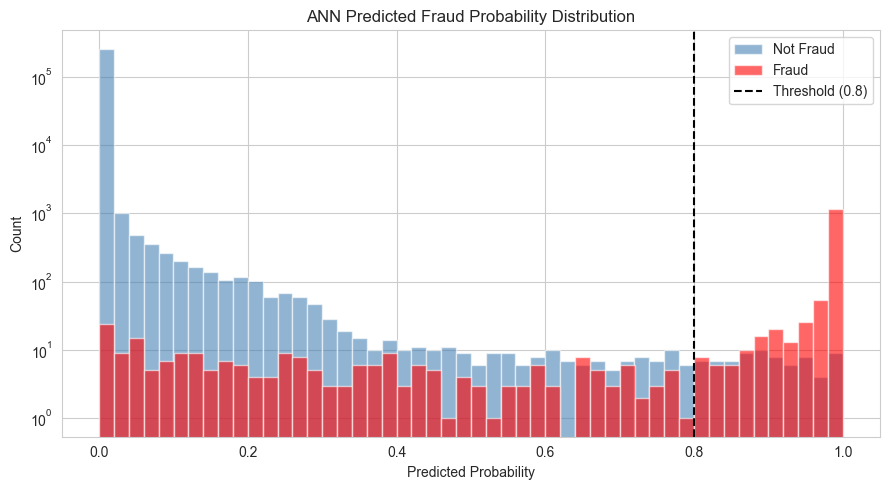

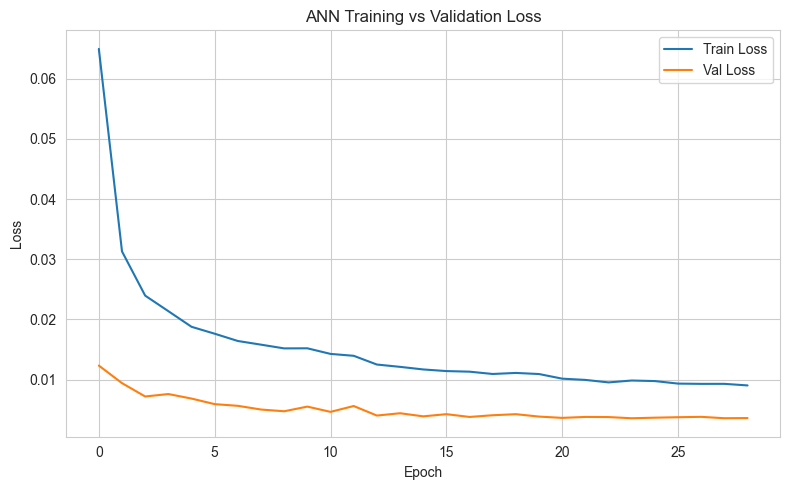

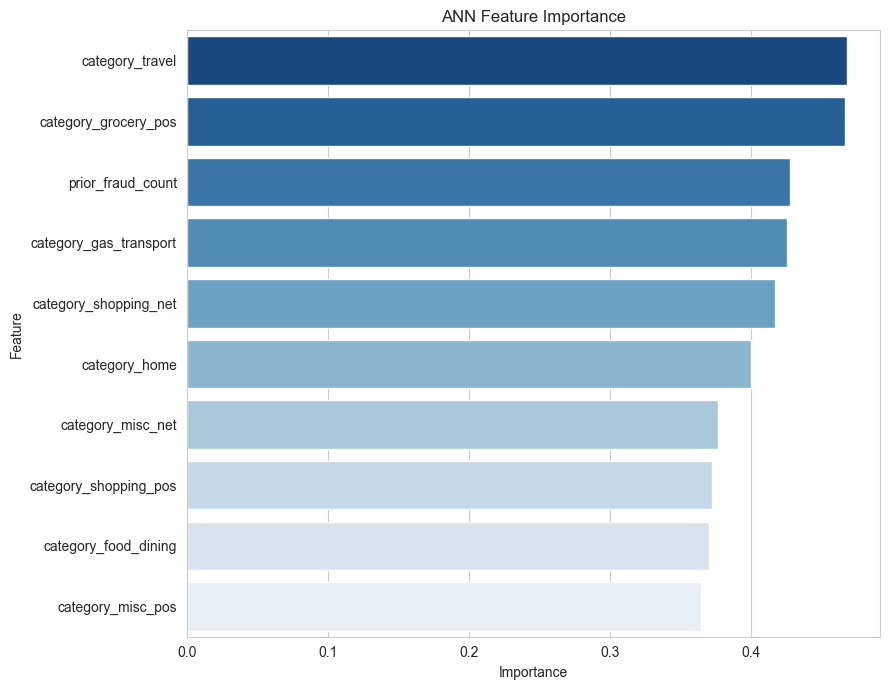


ANN Top 10 Features:
               Feature  Importance
       category_travel    0.468320
  category_grocery_pos    0.466741
     prior_fraud_count    0.427896
category_gas_transport    0.426132
 category_shopping_net    0.417434
         category_home    0.400590
     category_misc_net    0.376669
 category_shopping_pos    0.372744
  category_food_dining    0.370279
     category_misc_pos    0.364909


In [12]:
ann_metrics = evaluate_model("ANN", y_test, ann_pred, ann_proba, ANN_THRESHOLD)
plot_diagnostics("ANN", y_test, ann_proba, ANN_THRESHOLD, "purple", ann_metrics, save_prefix="ANN")

plt.figure(figsize=(8, 5))
plt.plot(ann_history.history["loss"], label="Train Loss")
plt.plot(ann_history.history["val_loss"], label="Val Loss")
plt.title("ANN Training vs Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.tight_layout()
plt.savefig("output/ANN_training_loss.png", dpi=150, bbox_inches="tight")
plt.show()

# ANN has no built-in feature_importances_; approximate with mean absolute
# first-layer weight magnitude per input feature.
first_dense = next(
    l for l in ann.layers if len(l.get_weights()) > 0 and len(l.get_weights()[0].shape) == 2
)
ann_importance = np.abs(first_dense.get_weights()[0]).mean(axis=1)
ann_importance_df = (
    pd.DataFrame({"Feature": ann_feature_names, "Importance": ann_importance})
    .sort_values("Importance", ascending=False)
    .reset_index(drop=True)
)

plot_feature_importance("ANN", ann_importance_df, "Blues_r", save_prefix="ANN")

**Result: Precision 0.9460, Recall 0.8544, F1 0.8978, AUC-ROC 0.9987.**
1,314 of 1,538 fraud cases caught, 224 missed, 75 false alarms. The
threshold (0.80) was re-swept from scratch after the leak-safety fix and
the move to a chronological split changed the model's score distribution
enough that the old threshold no longer landed anywhere near the best
tradeoff. A solid result on its own, though it turns out to be the
weakest of the three models on most metrics, a gap the statistical tests
and error analysis later in this notebook look into rather than just
note and move past.

**Why look at this on top of precision and recall:** precision,
recall, and F1 describe the tradeoff at the one threshold actually
chosen, they don't show what happens to real dollars, or to real
customers, if that threshold moves. The table below checks that
directly for each model: how the missed-fraud dollar total shifts as the
threshold goes up or down, alongside the false-positive count at that
same threshold. False positives aren't free either, each one is a real
customer's legitimate transaction wrongly flagged, a bad experience no
matter how the case eventually gets resolved. So the real question a
threshold has to answer is a trade: how much missed-fraud dollar risk is
worth accepting for how many fewer customers get wrongly flagged, not
where precision and recall land individually. In several of the tables
below, a small increase in missed fraud buys a much larger drop in false
positives, worth taking even though the fraud-detection number alone
looks slightly worse.

In [13]:
def missed_fraud_by_threshold(proba, y_true, X_test_idx, thresholds):
    """Missed-fraud dollar profile at each threshold (sum/mean/median/mode),
    plus the false-positive count at that same threshold, on a fixed grid.
    Both error types are shown together because they move in opposite
    directions as the threshold changes, this is what actually decides
    where a threshold should sit, not either number on its own."""
    y_arr = y_true.values
    rows = []
    for t in thresholds:
        pred = (proba >= t).astype(int)
        fn_idx = X_test_idx[(y_arr == 1) & (pred == 0)]
        n_fp = int(((y_arr == 0) & (pred == 1)).sum())
        amts = df.loc[fn_idx, "amt"].values
        if len(amts) == 0:
            continue
        mode_val = pd.Series(amts).mode()
        rows.append({
            "threshold": t,
            "n_missed": len(amts),
            "n_fp": n_fp,
            "sum_$": amts.sum(),
            "mean_$": amts.mean(),
            "median_$": np.median(amts),
            "mode_$": mode_val.iloc[0] if not mode_val.empty else np.nan,
        })
    return pd.DataFrame(rows)


fn_threshold_grid = [0.10, 0.20, 0.30, 0.40, 0.50, 0.60, 0.70, 0.80, 0.90]
ann_fn_table = missed_fraud_by_threshold(ann_proba, y_test, X_test.index, fn_threshold_grid)
print(ann_fn_table.round(2).to_string(index=False))

 threshold  n_missed  n_fp    sum_$  mean_$  median_$  mode_$
       0.1        60  1384  7434.56  123.91     19.70   10.33
       0.2        96   659 14449.08  150.51     20.81   10.33
       0.3       126   323 18304.48  145.27     20.96   10.33
       0.4       153   237 28609.88  186.99     21.48   10.33
       0.5       172   186 34019.74  197.79     21.80   10.33
       0.6       188   148 39939.62  212.44     22.36   10.33
       0.7       207   113 48086.22  232.30     22.97   10.33
       0.8       224    75 56497.79  252.22     23.56   10.33
       0.9       270    35 82721.15  306.37     50.68   10.33


The median barely moves (roughly `$20-24` the whole way from 0.10 to 0.80),
so most of what ANN misses is small no matter where the threshold sits.
The mean is what actually moves: it climbs steadily and then jumps
past 0.80 (median itself jumps to `$50.68` at 0.90), meaning the model starts
missing meaningfully larger fraud once the threshold gets that high, not
just a few more small cases.

## 7. Model 2: Random Forest

**Hyperparameter tuning:** the configuration below wasn't hand-picked. A
grid search over `class_weight` × `min_samples_split`/`min_samples_leaf`
(holding `n_estimators`/`max_depth` fixed) found this combination gave the
best F1 of the entire grid, improving both precision and recall over the
previous configuration at the same time, not a trade-off. The threshold
itself was re-swept separately (see below), since it needed to move once
the leak-safety fix and the chronological split changed what RF's scores
actually look like.

In [14]:
RF_THRESHOLD = 0.50

rf = RandomForestClassifier(
    n_estimators=200, max_depth=15, min_samples_split=10, min_samples_leaf=5,
    max_features="sqrt", class_weight={0: 1, 1: 20}, random_state=SEED, n_jobs=-1,
)
rf.fit(tree_X_train, y_train)

rf_proba = rf.predict_proba(tree_X_test)[:, 1]
rf_pred = (rf_proba >= RF_THRESHOLD).astype(int)

Random Forest  CLASSIFICATION REPORT (threshold=0.5)
              precision    recall  f1-score   support

   Not Fraud       1.00      1.00      1.00    257797
       Fraud       0.89      0.84      0.86      1538

    accuracy                           1.00    259335
   macro avg       0.94      0.92      0.93    259335
weighted avg       1.00      1.00      1.00    259335

AUC-ROC: 0.9975
True Negatives  (correctly allowed): 257632
False Positives (wrongly blocked):   165
False Negatives (missed fraud):      250  <- most costly
True Positives  (caught fraud):      1288


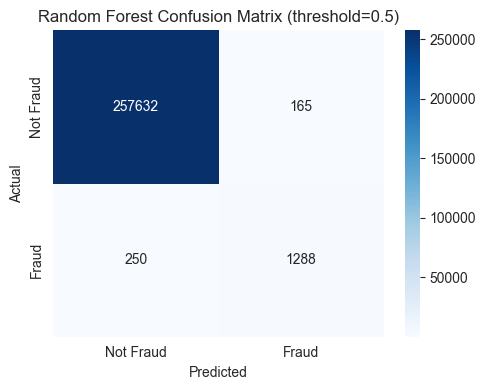

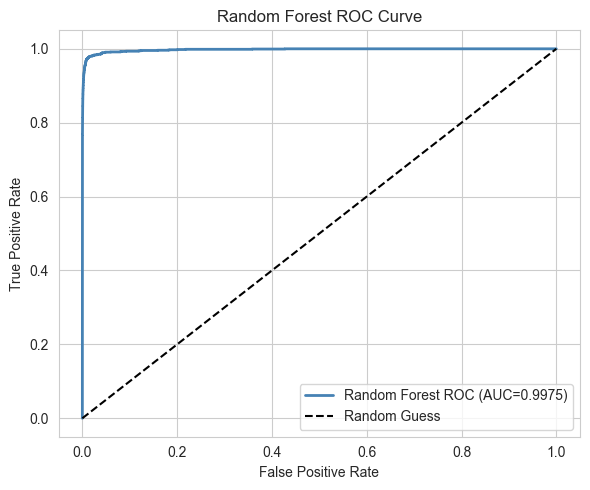

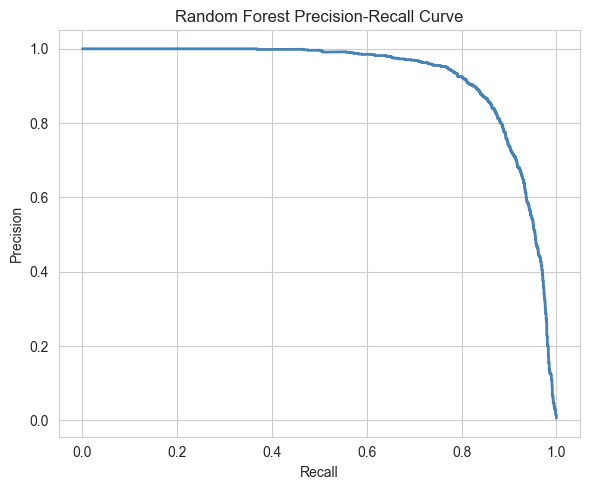

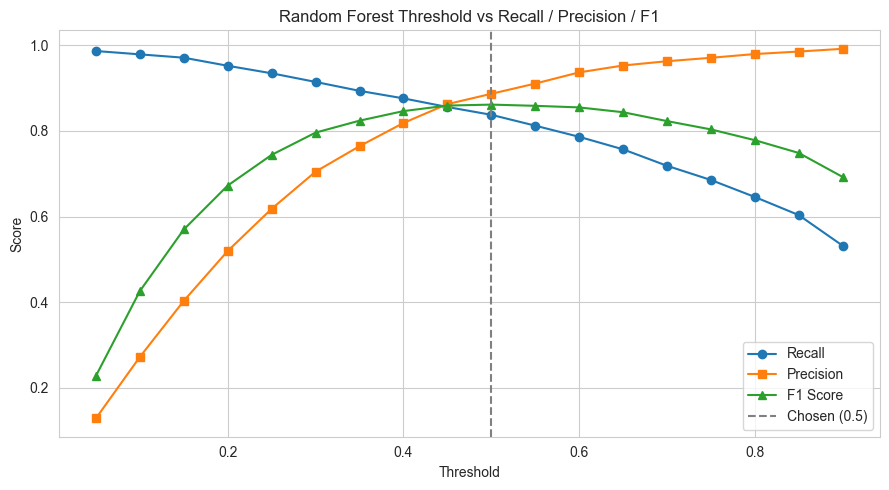

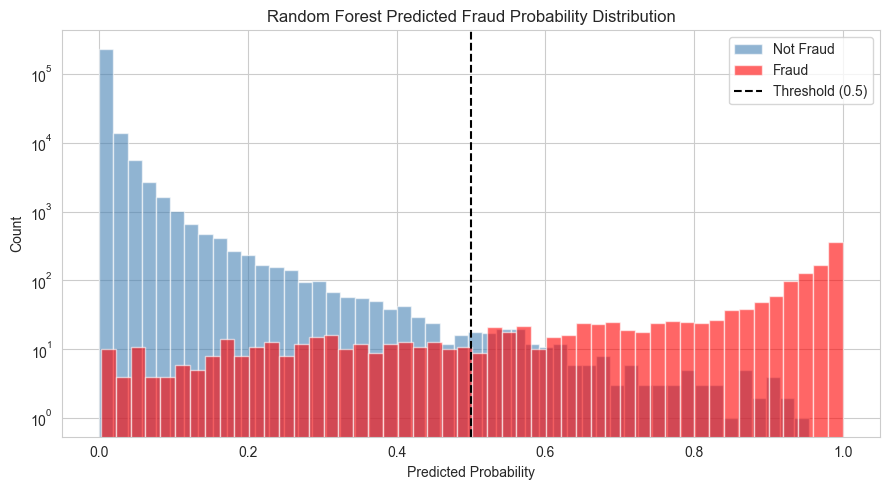

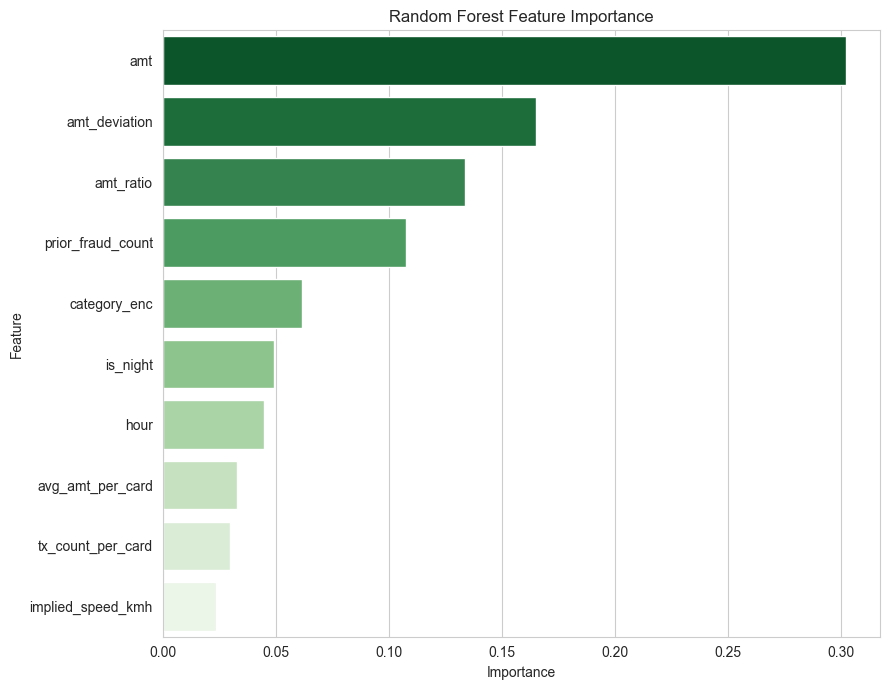


Random Forest Top 10 Features:
          Feature  Importance
              amt    0.302328
    amt_deviation    0.165156
        amt_ratio    0.133883
prior_fraud_count    0.107758
     category_enc    0.061506
         is_night    0.049415
             hour    0.044780
 avg_amt_per_card    0.033119
tx_count_per_card    0.029964
implied_speed_kmh    0.023390


In [15]:
rf_metrics = evaluate_model("Random Forest", y_test, rf_pred, rf_proba, RF_THRESHOLD)
plot_diagnostics("Random Forest", y_test, rf_proba, RF_THRESHOLD, "steelblue", rf_metrics, save_prefix="RF")

rf_importance_df = (
    pd.DataFrame({"Feature": tree_features, "Importance": rf.feature_importances_})
    .sort_values("Importance", ascending=False)
    .reset_index(drop=True)
)
plot_feature_importance("Random Forest", rf_importance_df, "Greens_r", save_prefix="RF")

**Result: Precision 0.8864, Recall 0.8375, F1 0.8613, AUC-ROC 0.9975.**
1,288 of 1,538 fraud cases caught, 250 missed, 165 false alarms. The
weakest of the three, and not by a narrow margin: RF raises more than
twice as many false alarms as either other model (165 against 75 each)
while catching the least fraud of the three. Section 10 tests whether that
gap is a real difference or an artifact of this particular test set.

In [16]:
rf_fn_table = missed_fraud_by_threshold(rf_proba, y_test, X_test.index, fn_threshold_grid)
print(rf_fn_table.round(2).to_string(index=False))

 threshold  n_missed  n_fp     sum_$  mean_$  median_$  mode_$
       0.1        33  4020   2876.50   87.17     21.53    7.21
       0.2        74  1353   7074.22   95.60     21.04   23.84
       0.3       132   589  15972.75  121.01     21.34   22.71
       0.4       191   299  31682.87  165.88     22.10   22.10
       0.5       250   165  51959.58  207.84     23.08    8.29
       0.6       329    82  76740.44  233.25     23.16    8.22
       0.7       433    43 114105.03  263.52     47.91    7.24
       0.8       545    21 159641.77  292.92    112.90    7.24
       0.9       720     7 246529.51  342.40    255.60    7.24


The same flat-median pattern shows up here, but it breaks down sooner than
ANN's did: RF's median jumps to `$47.91` already at 0.70 and to `$112.90` at
0.80, a full step earlier than ANN's equivalent jump. RF starts missing
real money at a lower threshold than the other two models do, consistent
with it being the weakest model overall on this setup.

## 8. Model 3: XGBoost (Gradient Boosting)

**Early stopping and the estimator cap:** `n_estimators` is set generously
high (1,500) together with `early_stopping_rounds=20`, so training stops
on its own once validation logloss goes 20 rounds without improving,
restoring the best-performing round rather than the last one. The cap
being high matters: set too low, the model could still be improving on
validation loss when training gets cut off, and that improvement is left
on the table with no sign it happened. A high cap paired with early
stopping lets the data decide the real number of rounds instead, which the
validation curve below confirms directly.

The validation split used for early stopping is carved from the
*training* data only (`gb_X_fit`/`gb_X_val`, a 90/10 split), never from
`tree_X_test`. Otherwise early stopping would be quietly looking at the
set used for final evaluation, the same leakage risk `validation_split=0.1`
avoids for the ANN above.

In [17]:
GB_THRESHOLD = 0.50
GB_SCALE_POS_WEIGHT = 5

gb_X_fit, gb_X_val, gb_y_fit, gb_y_val = train_test_split(
    tree_X_train, y_train, test_size=0.1, random_state=SEED, stratify=y_train
)

gb = XGBClassifier(
    n_estimators=1500, max_depth=6, learning_rate=0.05, subsample=0.8,
    colsample_bytree=0.8, min_child_weight=10, gamma=1,
    scale_pos_weight=GB_SCALE_POS_WEIGHT, random_state=SEED,
    eval_metric="logloss", early_stopping_rounds=20, verbosity=0,
)
gb.fit(gb_X_fit, gb_y_fit, eval_set=[(gb_X_val, gb_y_val)], verbose=False)
print(f"XGBoost stopped at {gb.best_iteration + 1} boosting rounds (cap was 1,500)")

gb_proba = gb.predict_proba(tree_X_test)[:, 1]
gb_pred = (gb_proba >= GB_THRESHOLD).astype(int)

XGBoost stopped at 944 boosting rounds (cap was 1,500)


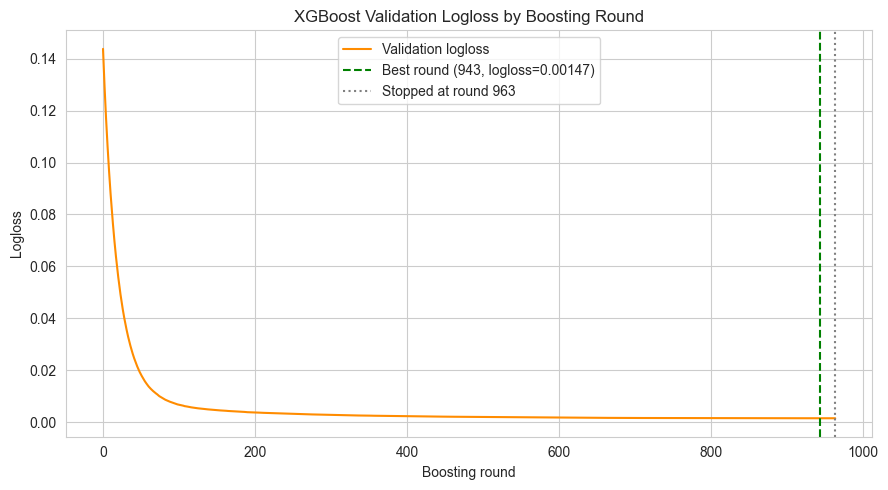

Best round: 943  |  Stopped at round: 963  |  Rounds after best with no improvement: 20 (patience=20)
Total rounds trained: 964  |  n_estimators cap was: 1,500


In [18]:
# Validation logloss by boosting round -- confirms early_stopping_rounds=20
# actually caught a real plateau, not an arbitrary cutoff.
gb_evals = gb.evals_result()["validation_0"]["logloss"]
gb_stopped_round = len(gb_evals) - 1

plt.figure(figsize=(9, 5))
plt.plot(range(len(gb_evals)), gb_evals, color="darkorange", label="Validation logloss")
plt.axvline(x=gb.best_iteration, color="green", linestyle="--",
            label=f"Best round ({gb.best_iteration}, logloss={gb.best_score:.5f})")
plt.axvline(x=gb_stopped_round, color="gray", linestyle=":",
            label=f"Stopped at round {gb_stopped_round}")
plt.title("XGBoost Validation Logloss by Boosting Round")
plt.xlabel("Boosting round")
plt.ylabel("Logloss")
plt.legend()
plt.tight_layout()
plt.savefig("output/xgb_validation_curve.png", dpi=150, bbox_inches="tight")
plt.show()

print(f"Best round: {gb.best_iteration}  |  Stopped at round: {gb_stopped_round}  "
      f"|  Rounds after best with no improvement: {gb_stopped_round - gb.best_iteration} "
      f"(patience=20)")
print(f"Total rounds trained: {len(gb_evals)}  |  n_estimators cap was: 1,500")

XGBoost  CLASSIFICATION REPORT (threshold=0.5)
              precision    recall  f1-score   support

   Not Fraud       1.00      1.00      1.00    257797
       Fraud       0.95      0.89      0.92      1538

    accuracy                           1.00    259335
   macro avg       0.97      0.95      0.96    259335
weighted avg       1.00      1.00      1.00    259335

AUC-ROC: 0.9994
True Negatives  (correctly allowed): 257722
False Positives (wrongly blocked):   75
False Negatives (missed fraud):      168  <- most costly
True Positives  (caught fraud):      1370


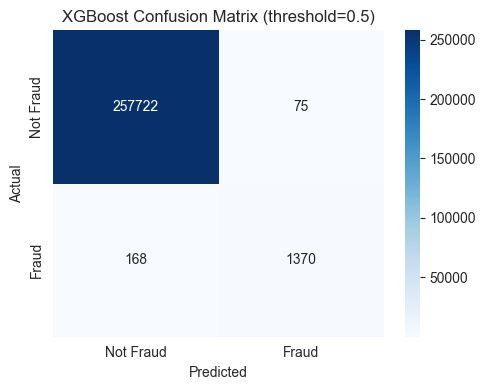

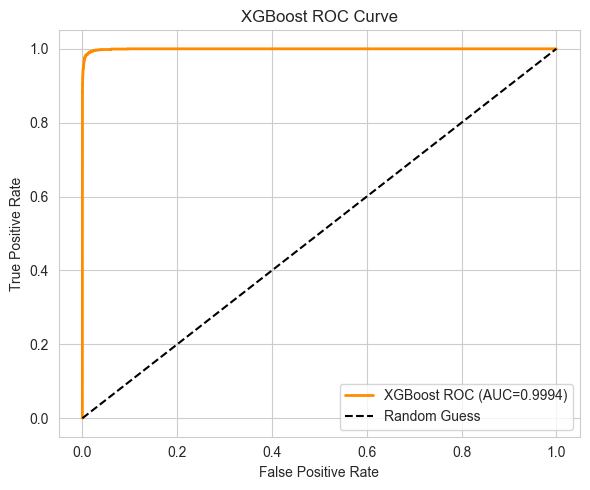

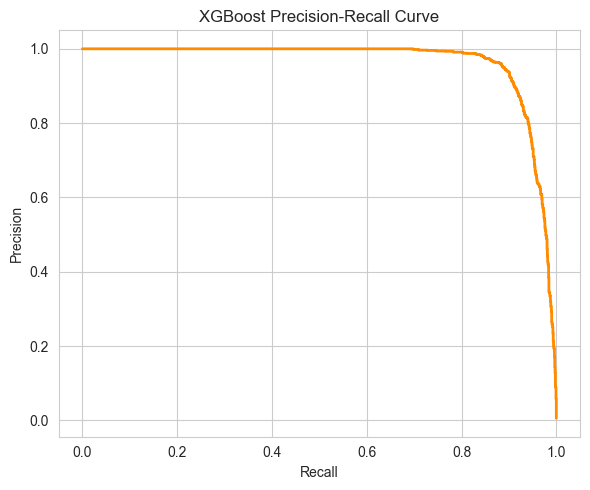

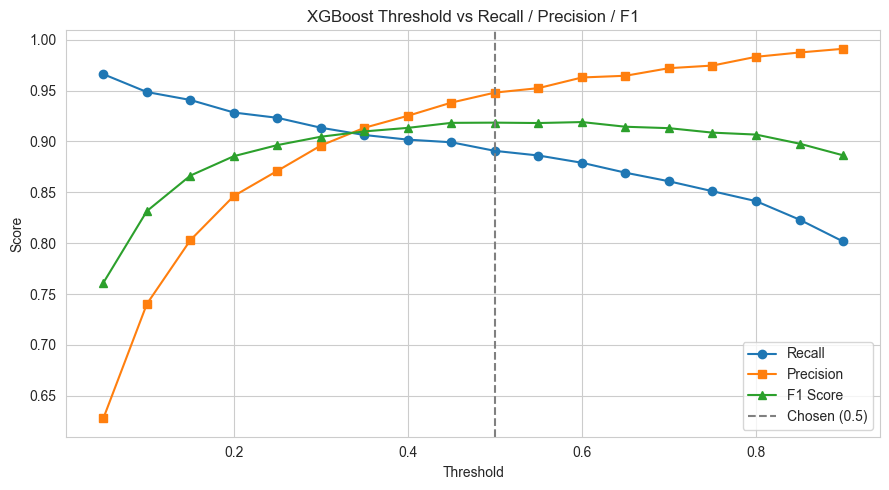

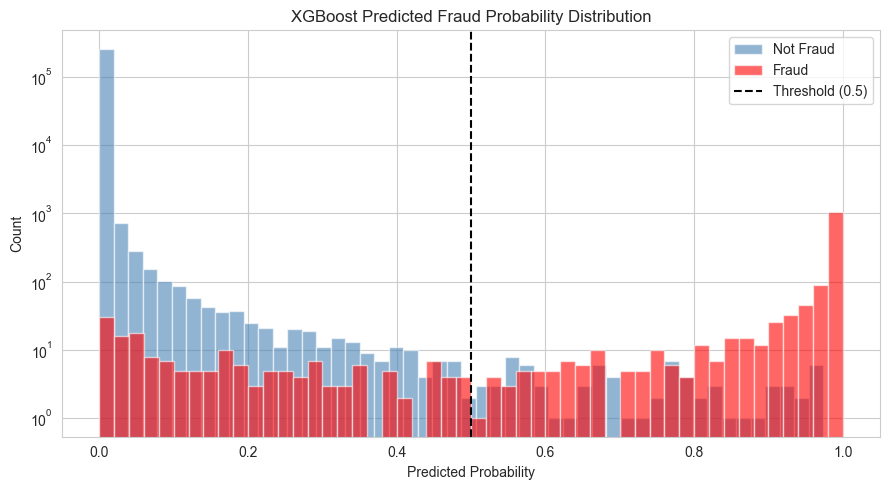

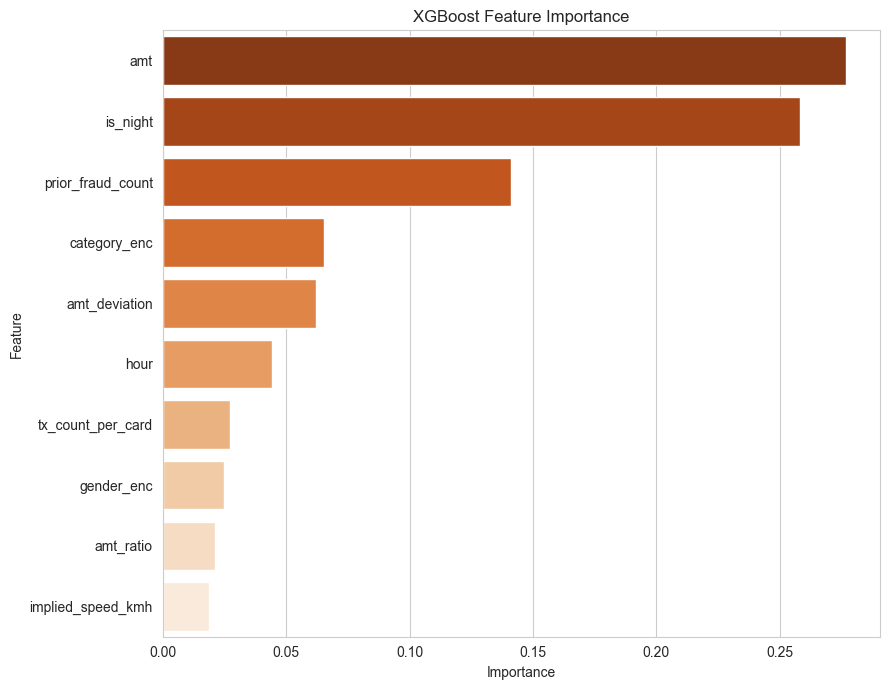


XGBoost Top 10 Features:
          Feature  Importance
              amt    0.276765
         is_night    0.258117
prior_fraud_count    0.141154
     category_enc    0.065563
    amt_deviation    0.062314
             hour    0.044122
tx_count_per_card    0.027245
       gender_enc    0.024652
        amt_ratio    0.021063
implied_speed_kmh    0.018642


In [19]:
gb_metrics = evaluate_model("XGBoost", y_test, gb_pred, gb_proba, GB_THRESHOLD)
plot_diagnostics("XGBoost", y_test, gb_proba, GB_THRESHOLD, "darkorange", gb_metrics, save_prefix="GB")

gb_importance_df = (
    pd.DataFrame({"Feature": tree_features, "Importance": gb.feature_importances_})
    .sort_values("Importance", ascending=False)
    .reset_index(drop=True)
)
plot_feature_importance("XGBoost", gb_importance_df, "Oranges_r", save_prefix="GB")

**Result: Precision 0.9481, Recall 0.8908, F1 0.9185, AUC-ROC 0.9994.**
1,370 of 1,538 fraud cases caught, 168 missed, 75 false alarms. The
strongest of the three: it catches the most fraud while raising exactly
the same 75 false alarms as the ANN, which is the combination neither
other model manages. The statistical tests ahead check that lead properly
rather than reading it off a bar chart.

In [20]:
gb_fn_table = missed_fraud_by_threshold(gb_proba, y_test, X_test.index, fn_threshold_grid)
print(gb_fn_table.round(2).to_string(index=False))

 threshold  n_missed  n_fp    sum_$  mean_$  median_$  mode_$
       0.1        79   512 11223.23  142.07     22.10   22.10
       0.2       110   259 19983.58  181.67     22.53   10.33
       0.3       133   163 25188.44  189.39     22.22   10.33
       0.4       151   112 28728.08  190.25     22.35   10.33
       0.5       168    75 33174.27  197.47     22.10   10.33
       0.6       186    52 40958.38  220.21     22.69   10.33
       0.7       214    38 47543.85  222.17     22.71    8.29
       0.8       244    22 62806.73  257.40     23.56    8.29
       0.9       305    11 91568.48  300.22     49.14    8.29


XGBoost's median stays in roughly the same `$22-24` band as ANN's all the
way through 0.80, and its jump at 0.90 (`$49.14`) lands a touch below
ANN's (`$50.68`) at that same point. RF breaks down much earlier, already
jumping at 0.70. So XGBoost isn't uniquely resistant here, ANN holds up
almost as well, but it's still the model whose threshold can be pushed
furthest before real money starts getting missed, consistent with its
lead everywhere else in this notebook.

## 9. Cross-Model Comparison

Side by side, before any statistical testing: precision/recall/F1,
AUC-ROC, and the raw missed-fraud/false-alarm counts for all three models
on the same test set.

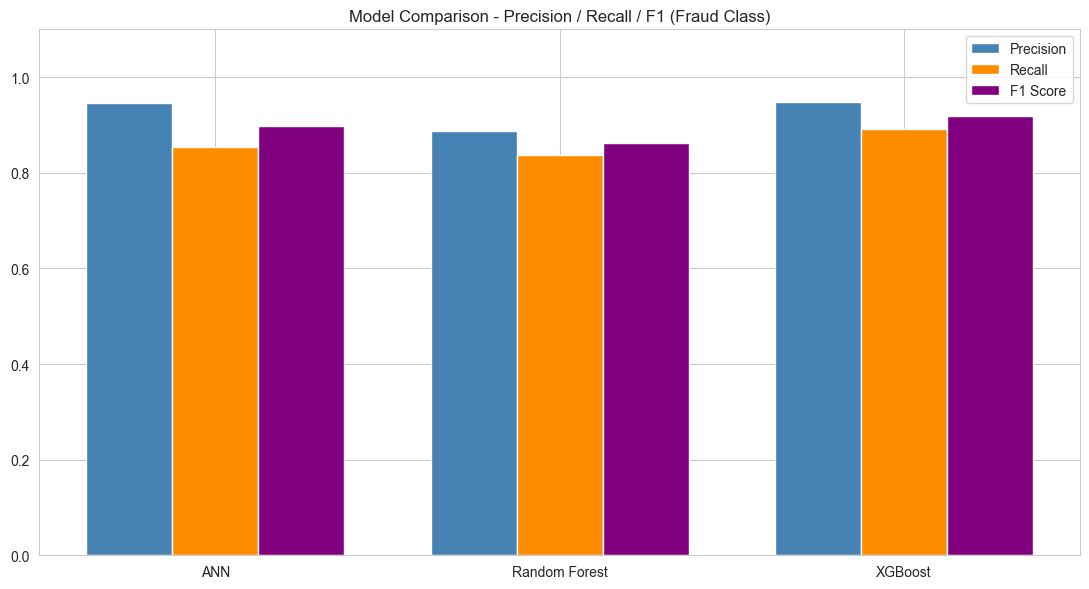

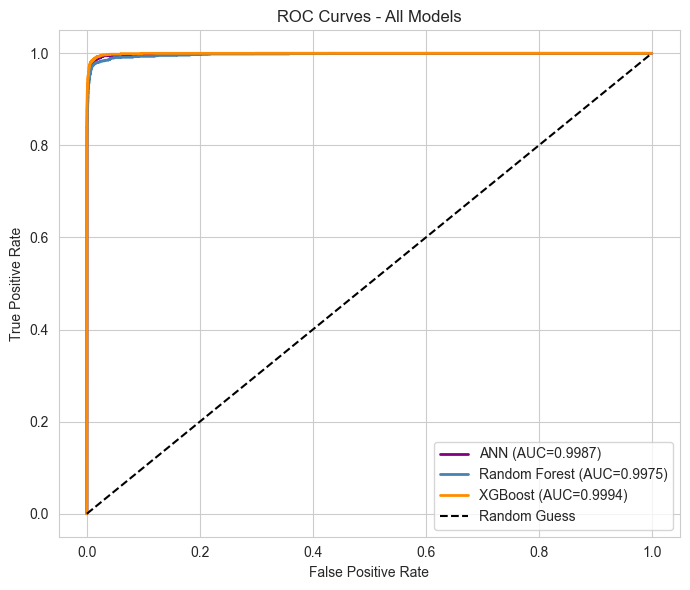

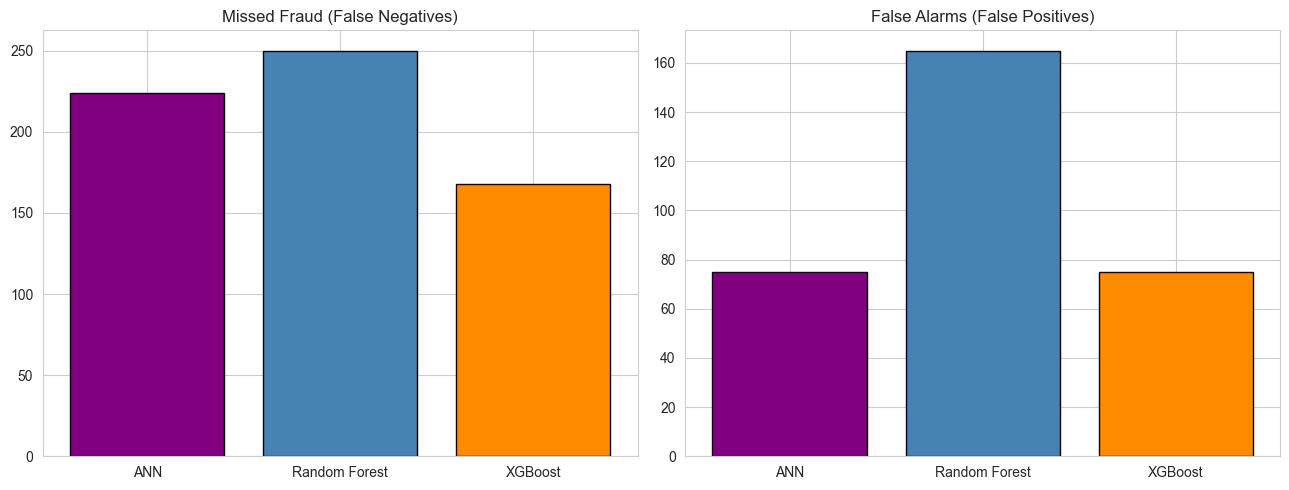

In [21]:
all_metrics = [ann_metrics, rf_metrics, gb_metrics]
model_names = [m["name"] for m in all_metrics]
model_colors = ["purple", "steelblue", "darkorange"]

precision_s = [m["precision"] for m in all_metrics]
recall_s = [m["recall"] for m in all_metrics]
f1_s = [m["f1"] for m in all_metrics]
auc_s = [m["auc"] for m in all_metrics]
fn_vals = [m["fn"] for m in all_metrics]
fp_vals = [m["fp"] for m in all_metrics]

x, width = np.arange(len(model_names)), 0.25
fig, ax = plt.subplots(figsize=(11, 6))
ax.bar(x - width, precision_s, width, label="Precision", color="steelblue")
ax.bar(x, recall_s, width, label="Recall", color="darkorange")
ax.bar(x + width, f1_s, width, label="F1 Score", color="purple")
ax.set_xticks(x)
ax.set_xticklabels(model_names)
ax.set_ylim(0, 1.1)
ax.set_title("Model Comparison - Precision / Recall / F1 (Fraud Class)")
ax.legend()
plt.tight_layout()
plt.savefig("output/model_comparison_bars.png", dpi=150, bbox_inches="tight")
plt.show()

plt.figure(figsize=(7, 6))
for m, color in zip(all_metrics, model_colors):
    plt.plot(m["fpr"], m["tpr"], color=color, lw=2, label=f"{m['name']} (AUC={m['auc']:.4f})")
plt.plot([0, 1], [0, 1], "k--", label="Random Guess")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves - All Models")
plt.legend(loc="lower right")
plt.tight_layout()
plt.savefig("output/roc_curves_all_models.png", dpi=150, bbox_inches="tight")
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].bar(model_names, fn_vals, color=model_colors, edgecolor="black")
axes[0].set_title("Missed Fraud (False Negatives)")
axes[1].bar(model_names, fp_vals, color=model_colors, edgecolor="black")
axes[1].set_title("False Alarms (False Positives)")
plt.tight_layout()
plt.savefig("output/fn_fp_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

In [22]:
summary_table = pd.DataFrame([
    {
        "Model": m["name"], "Precision": m["precision"], "Recall": m["recall"],
        "F1": m["f1"], "AUC-ROC": m["auc"], "Fraud Caught": m["tp"],
        "Missed Fraud": m["fn"], "Missed Fraud $": fn_dollar_sum(y_test, pred, test_amt),
        "False Alarms": m["fp"], "Threshold": m["threshold"],
    }
    for m, pred in zip(all_metrics, [ann_pred, rf_pred, gb_pred])
])
summary_table

,Model,Precision,Recall,F1,AUC-ROC,Fraud Caught,Missed Fraud,Missed Fraud $,False Alarms,Threshold
0,ANN,0.946004,0.854356,0.897848,0.998699,1314,224,56497.79,75,0.8
1,Random Forest,0.886442,0.837451,0.861250,0.997537,1288,250,51959.58,165,0.5
2,XGBoost,0.948097,0.890767,0.918538,0.999389,1370,168,33174.27,75,0.5


| Model | Precision | Recall | F1 | AUC-ROC | Caught | Missed | Missed Fraud $ | False Alarms |
|---|---|---|---|---|---|---|---|---|
| ANN | 0.9460 | 0.8544 | 0.8978 | 0.9987 | 1,314 | 224 | `$56,497.79` | 75 |
| Random Forest | 0.8864 | 0.8375 | 0.8613 | 0.9975 | 1,288 | 250 | `$51,959.58` | 165 |
| XGBoost | 0.9481 | 0.8908 | 0.9185 | 0.9994 | 1,370 | 168 | `$33,174.27` | 75 |

Precision and recall point to XGBoost, and the dollar column agrees: it
leaves `$33,174.27` in missed fraud against ANN's `$56,497.79` and RF's
`$51,959.58`.

That column needs one caveat before it gets over-read, though. Each model
sits at its own threshold here (ANN at 0.80, the other two at 0.50), so
part of that gap is threshold choice rather than model quality. ANN's own
table back in section 6 has it missing `$34,019.74` at threshold 0.50,
within 3% of XGBoost. The real separation between those two shows up on
the other side of the ledger: at that same 0.50 threshold, ANN raises 186
false alarms against XGBoost's 75. XGBoost is genuinely the better model,
it just wins by holding false alarms down at comparable recall rather than
by missing dramatically less money.

Which is the general lesson for reading any table like this one: precision
and recall describe one threshold's tradeoff, the dollar figure says what
that tradeoff costs, and comparing two models sitting at two different
thresholds measures the thresholds as much as the models. The next section
tests whether XGBoost's lead is a consistent difference or something that
could turn up by chance on this one test set.

## 10. Statistical Validation

Two different questions, two different tests:

- **Do the models actually make different mistakes, or do they just have
  different aggregate scores by chance?** Two models could show a
  small F1 gap while agreeing on 99% of individual transactions, in which
  case "model A is better" is a real but narrow claim with little to gain
  from combining them. McNemar's test checks this directly: it looks at
  the transactions the two models disagree on (one right, one wrong) and
  tests whether those disagreements are lopsided enough to be more than
  chance. Cochran's Q extends this to all three models at once as a
  single omnibus test, for a reason explained below.
- **Are each model's probability scores separating fraud from legitimate
  transactions, or just barely better than random?** A model could hit a
  precision/recall target at one specific threshold while its underlying
  scores are only weakly separated overall, which would be a problem if
  the threshold ever needs to move. Mann-Whitney U tests whether the
  fraud-score distribution and the legitimate-score distribution are
  really different, independent of any specific threshold.

Both at α = 0.05.

In [23]:
ALPHA = 0.05


def mcnemar_test(pred_a, pred_b, name_a, name_b, y_true):
    """2x2 contingency table + McNemar's test between two classifiers."""
    correct_a = pred_a == y_true.values
    correct_b = pred_b == y_true.values
    b00 = np.sum(correct_a & correct_b)
    b01 = np.sum(correct_a & ~correct_b)
    b10 = np.sum(~correct_a & correct_b)
    b11 = np.sum(~correct_a & ~correct_b)

    result = mcnemar([[b00, b01], [b10, b11]], exact=False, correction=True)
    sig = "SIGNIFICANT" if result.pvalue < ALPHA else "NOT SIGNIFICANT"

    print(f"\n{name_a} vs {name_b}")
    print(f"  Both correct: {b00:,} | {name_a} only: {b01:,} | {name_b} only: {b10:,} | Both wrong: {b11:,}")
    print(f"  Chi^2 = {result.statistic:.4f}  p = {result.pvalue:.6f}  -> {sig}")
    return result.pvalue


def mann_whitney_test(proba, name, y_true):
    """Fraud vs. legitimate score-distribution separation test."""
    fraud_scores = proba[y_true.values == 1]
    legit_scores = proba[y_true.values == 0]
    stat, p = mannwhitneyu(fraud_scores, legit_scores, alternative="greater")
    effect = 1 - (2 * stat) / (len(fraud_scores) * len(legit_scores))
    sig = "SIGNIFICANT" if p < ALPHA else "NOT SIGNIFICANT"

    print(f"\n{name}")
    print(f"  Fraud  mean={fraud_scores.mean():.4f} median={np.median(fraud_scores):.4f}")
    print(f"  Legit  mean={legit_scores.mean():.4f} median={np.median(legit_scores):.4f}")
    print(f"  U = {stat:.2f}  p = {p:.2e}  effect size r = {effect:.4f}  -> {sig}")
    return p, effect


print("=" * 62)
print("McNEMAR'S TEST -- Pairwise Model Comparison")
print("H0: Both models have the same error pattern")
print("=" * 62)
p_ann_rf = mcnemar_test(ann_pred, rf_pred, "ANN", "RF", y_test)
p_ann_gb = mcnemar_test(ann_pred, gb_pred, "ANN", "XGBoost", y_test)
p_rf_gb = mcnemar_test(rf_pred, gb_pred, "RF", "XGBoost", y_test)

print("\n" + "=" * 62)
print("MANN-WHITNEY U TEST -- Fraud vs Legitimate Probability Scores")
print("H0: Fraud and legitimate score distributions are the same")
print("=" * 62)
p_ann_mw, eff_ann = mann_whitney_test(ann_proba, "ANN", y_test)
p_rf_mw, eff_rf = mann_whitney_test(rf_proba, "Random Forest", y_test)
p_gb_mw, eff_gb = mann_whitney_test(gb_proba, "XGBoost", y_test)

statistical_summary = pd.DataFrame({
    "Test": ["McNemar: ANN vs RF", "McNemar: ANN vs XGB", "McNemar: RF vs XGB",
              "Mann-Whitney: ANN", "Mann-Whitney: RF", "Mann-Whitney: XGB"],
    "p-value": [f"{p_ann_rf:.6f}", f"{p_ann_gb:.6f}", f"{p_rf_gb:.6f}",
                 f"{p_ann_mw:.2e}", f"{p_rf_mw:.2e}", f"{p_gb_mw:.2e}"],
    "Significant (a=0.05)": [
        p < ALPHA for p in [p_ann_rf, p_ann_gb, p_rf_gb, p_ann_mw, p_rf_mw, p_gb_mw]
    ],
})
print("\n" + "=" * 62 + "\nSUMMARY TABLE\n" + "=" * 62)
print(statistical_summary.to_string(index=False))

McNEMAR'S TEST -- Pairwise Model Comparison
H0: Both models have the same error pattern

ANN vs RF
  Both correct: 258,838 | ANN only: 198 | RF only: 82 | Both wrong: 217
  Chi^2 = 47.2321  p = 0.000000  -> SIGNIFICANT

ANN vs XGBoost
  Both correct: 258,969 | ANN only: 67 | XGBoost only: 123 | Both wrong: 176
  Chi^2 = 15.9211  p = 0.000066  -> SIGNIFICANT

RF vs XGBoost
  Both correct: 258,866 | RF only: 54 | XGBoost only: 226 | Both wrong: 189
  Chi^2 = 104.4321  p = 0.000000  -> SIGNIFICANT

MANN-WHITNEY U TEST -- Fraud vs Legitimate Probability Scores
H0: Fraud and legitimate score distributions are the same

ANN
  Fraud  mean=0.8890 median=0.9994
  Legit  mean=0.0021 median=0.0000
  U = 395975936.00  p = 0.00e+00  effect size r = -0.9974  -> SIGNIFICANT

Random Forest
  Fraud  mean=0.7848 median=0.9134
  Legit  mean=0.0097 median=0.0015
  U = 395515259.00  p = 0.00e+00  effect size r = -0.9951  -> SIGNIFICANT

XGBoost
  Fraud  mean=0.8783 median=0.9966
  Legit  mean=0.0010 median

**All three pairwise comparisons come back significant.**

| Pair | Both correct | A-only correct | B-only correct | Both wrong | p-value |
|---|---|---|---|---|---|
| ANN vs RF | 258,838 | ANN: 198 | RF: 82 | 217 | 0.000000 |
| ANN vs XGBoost | 258,969 | ANN: 67 | XGB: 123 | 176 | 0.000066 |
| RF vs XGBoost | 258,866 | RF: 54 | XGB: 226 | 189 | 0.000000 |

Every pair disagrees in a real, lopsided way, not by chance. ANN beats RF
head-to-head (198 cases only ANN gets right, against only 82 the other
way), XGBoost beats RF by an even wider margin (226 vs. 54), and XGBoost
edges out ANN too (123 vs. 67), the smallest gap of the three but still
real at p=0.000066. Three genuinely different models making different
mistakes, not the same model wearing three names.

**Why Cochran's Q, on top of the three McNemar's tests above:** running
three separate pairwise tests, each at its own 5% significance threshold,
pushes the real chance of a false "significant difference" somewhere up
to roughly 14%, not 5%. That's the standard multiple-comparisons problem.
Cochran's Q fixes it with one omnibus test across all three models at
once, on an (N × 3) matrix of whether each model got each transaction
right. It asks a single question, whether all three models have the same
error rate, the same relationship one-way ANOVA has to a pile of pairwise
t-tests. A significant Q result is what makes it fair to read the three
pairwise McNemar's tests above as valid follow-up comparisons, rather
than three uncorrected p-values standing on their own.

In [24]:
correct_matrix = np.column_stack([
    (ann_pred == y_test.values).astype(int),
    (rf_pred == y_test.values).astype(int),
    (gb_pred == y_test.values).astype(int),
])

q_result = cochrans_q(correct_matrix)
q_sig = "SIGNIFICANT" if q_result.pvalue < ALPHA else "NOT SIGNIFICANT"

print("=" * 62)
print("COCHRAN'S Q TEST -- Omnibus 3-Model Comparison")
print("H0: ANN, RF, and XGBoost all have the same error rate")
print("=" * 62)
print(f"Q = {q_result.statistic:.4f}  df = 2  p = {q_result.pvalue:.6f}  -> {q_sig}")

COCHRAN'S Q TEST -- Omnibus 3-Model Comparison
H0: ANN, RF, and XGBoost all have the same error rate
Q = 123.1360  df = 2  p = 0.000000  -> SIGNIFICANT


**Q = 123.1360, df = 2, p ≈ 0.000000: significant.** All three models
have different error rates from one another, which is what licenses
reading the three pairwise McNemar's tests above as valid follow-up
comparisons rather than three uncorrected 5%-risk tests standing alone.

## 11. Overfitting Check: Train vs. Test Performance

Before trusting any of the numbers above: are these models actually
generalizing, or did they just memorize the training set? The check is
simple: evaluate each model on the data it was trained on and compare
those numbers to the test-set numbers already computed. AUC gap is the
more reliable signal here, not precision/recall gap, because precision and
recall both depend on the exact threshold chosen, so a gap there can
reflect threshold sensitivity as much as real overfitting; AUC is
threshold-free and measures the ranking quality of the scores directly.

In [25]:
ann_train_proba = ann.predict(ann_X_train, verbose=0).flatten()
ann_train_pred = (ann_train_proba >= ANN_THRESHOLD).astype(int)
ann_train_metrics = evaluate_model("ANN (TRAIN)", y_train, ann_train_pred, ann_train_proba, ANN_THRESHOLD)

rf_train_proba = rf.predict_proba(tree_X_train)[:, 1]
rf_train_pred = (rf_train_proba >= RF_THRESHOLD).astype(int)
rf_train_metrics = evaluate_model("Random Forest (TRAIN)", y_train, rf_train_pred, rf_train_proba, RF_THRESHOLD)

gb_train_proba = gb.predict_proba(tree_X_train)[:, 1]
gb_train_pred = (gb_train_proba >= GB_THRESHOLD).astype(int)
gb_train_metrics = evaluate_model("XGBoost (TRAIN)", y_train, gb_train_pred, gb_train_proba, GB_THRESHOLD)

ANN (TRAIN)  CLASSIFICATION REPORT (threshold=0.8)
              precision    recall  f1-score   support

   Not Fraud       1.00      1.00      1.00   1031372
       Fraud       0.97      0.89      0.93      5968

    accuracy                           1.00   1037340
   macro avg       0.98      0.95      0.96   1037340
weighted avg       1.00      1.00      1.00   1037340

AUC-ROC: 0.9996
True Negatives  (correctly allowed): 1031190
False Positives (wrongly blocked):   182
False Negatives (missed fraud):      627  <- most costly
True Positives  (caught fraud):      5341
Random Forest (TRAIN)  CLASSIFICATION REPORT (threshold=0.5)
              precision    recall  f1-score   support

   Not Fraud       1.00      1.00      1.00   1031372
       Fraud       0.95      0.97      0.96      5968

    accuracy                           1.00   1037340
   macro avg       0.97      0.98      0.98   1037340
weighted avg       1.00      1.00      1.00   1037340

AUC-ROC: 0.9999
True Negatives  (

In [26]:
overfit_check = pd.DataFrame([
    {
        "Model": name,
        "Train Precision": tr["precision"], "Test Precision": te["precision"],
        "Precision Gap": tr["precision"] - te["precision"],
        "Train Recall": tr["recall"], "Test Recall": te["recall"],
        "Recall Gap": tr["recall"] - te["recall"],
        "Train AUC": tr["auc"], "Test AUC": te["auc"],
        "AUC Gap": tr["auc"] - te["auc"],
    }
    for name, tr, te in [
        ("ANN", ann_train_metrics, ann_metrics),
        ("Random Forest", rf_train_metrics, rf_metrics),
        ("XGBoost", gb_train_metrics, gb_metrics),
    ]
])
print(overfit_check.round(4).to_string(index=False))
print("\nRule of thumb: gaps under ~0.02-0.03 are normal for tree ensembles on")
print("data this size. Bigger gaps -- especially train AUC near 1.0 while test")
print("AUC is meaningfully lower -- would be the actual overfitting signal.")

        Model  Train Precision  Test Precision  Precision Gap  Train Recall  Test Recall  Recall Gap  Train AUC  Test AUC  AUC Gap
          ANN           0.9670          0.9460         0.0210        0.8949       0.8544      0.0406     0.9996    0.9987   0.0009
Random Forest           0.9461          0.8864         0.0596        0.9670       0.8375      0.1295     0.9999    0.9975   0.0024
      XGBoost           0.9900          0.9481         0.0419        0.9945       0.8908      0.1037     1.0000    0.9994   0.0006

Rule of thumb: gaps under ~0.02-0.03 are normal for tree ensembles on
data this size. Bigger gaps -- especially train AUC near 1.0 while test
AUC is meaningfully lower -- would be the actual overfitting signal.


| Model | Train AUC | Test AUC | AUC Gap | Recall Gap |
|---|---|---|---|---|
| ANN | 0.9996 | 0.9987 | 0.0009 | 0.0405 |
| Random Forest | 0.9999 | 0.9975 | 0.0024 | 0.1295 |
| XGBoost | 1.0000 | 0.9994 | 0.0006 | 0.1037 |

All three AUC gaps come in under 0.003, so on the threshold-free signal
none of these models is meaningfully overfitting.

The recall gaps are wider and worth explaining rather than waving past
(RF 0.1295, XGBoost 0.1037). Each model fits its training rows more
closely than unseen ones, so training-set fraud scores sit further above
the cutoff and more of them clear it. That lifts recall on data the model
has already seen without improving how well it *ranks* fraud above
legitimate transactions, which is exactly why the AUC gap stays near zero
while the recall gap does not. A model that had genuinely memorized the
training set would show both gaps widening together. Only one of them
moves here, so the answer to the overfitting question is still no.

## 12. Does Simply Combining All Three Models Beat XGBoost Alone?

The statistical tests above showed the three models disagree on real
cases. The next question is whether just averaging them together makes
use of that disagreement. Three combination strategies, tested the same
way as the individual models above:

- **Simple average:** equal weight to all three.
- **F1-weighted average:** weights come from each model's own F1 score
  this run, not hand-picked, so a stronger model automatically gets more
  say.
- **Majority vote:** flagged as fraud if at least 2 of 3 models say so,
  each using its own already-tuned threshold.

One caveat upfront: majority vote's AUC will look artificially low next
to the other rows, because vote-count/3 is a 4-value step function (0,
1/3, 2/3, 1), not a smooth probability score, and AUC needs fine-grained
ranking that a 4-value score can't give it. Read its precision/recall
against the others, not its AUC.

In [27]:
# Simple average ensemble
ensemble_proba_avg = (ann_proba + rf_proba + gb_proba) / 3
ensemble_pred_avg = (ensemble_proba_avg >= 0.5).astype(int)
ensemble_avg_metrics = evaluate_model(
    "Ensemble (simple avg)", y_test, ensemble_pred_avg, ensemble_proba_avg, 0.5
)

# F1-weighted average ensemble
f1_weights = {"ANN": ann_metrics["f1"], "Random Forest": rf_metrics["f1"], "XGBoost": gb_metrics["f1"]}
total_f1 = sum(f1_weights.values())
w_ann = f1_weights["ANN"] / total_f1
w_rf = f1_weights["Random Forest"] / total_f1
w_gb = f1_weights["XGBoost"] / total_f1
print(f"F1-derived weights -- ANN: {w_ann:.3f}, RF: {w_rf:.3f}, XGBoost: {w_gb:.3f}")

ensemble_proba_weighted = w_ann * ann_proba + w_rf * rf_proba + w_gb * gb_proba
ensemble_pred_weighted = (ensemble_proba_weighted >= 0.5).astype(int)
ensemble_weighted_metrics = evaluate_model(
    "Ensemble (F1-weighted avg)", y_test, ensemble_pred_weighted, ensemble_proba_weighted, 0.5
)

# Majority vote ensemble
vote_count = ann_pred.astype(int) + rf_pred.astype(int) + gb_pred.astype(int)
ensemble_pred_vote = (vote_count >= 2).astype(int)
ensemble_proba_vote = vote_count / 3
ensemble_vote_metrics = evaluate_model(
    "Ensemble (majority vote >=2/3)", y_test, ensemble_pred_vote, ensemble_proba_vote, 2 / 3
)

Ensemble (simple avg)  CLASSIFICATION REPORT (threshold=0.5)
              precision    recall  f1-score   support

   Not Fraud       1.00      1.00      1.00    257797
       Fraud       0.94      0.89      0.92      1538

    accuracy                           1.00    259335
   macro avg       0.97      0.95      0.96    259335
weighted avg       1.00      1.00      1.00    259335

AUC-ROC: 0.9987
True Negatives  (correctly allowed): 257711
False Positives (wrongly blocked):   86
False Negatives (missed fraud):      166  <- most costly
True Positives  (caught fraud):      1372
F1-derived weights -- ANN: 0.335, RF: 0.322, XGBoost: 0.343
Ensemble (F1-weighted avg)  CLASSIFICATION REPORT (threshold=0.5)
              precision    recall  f1-score   support

   Not Fraud       1.00      1.00      1.00    257797
       Fraud       0.94      0.89      0.92      1538

    accuracy                           1.00    259335
   macro avg       0.97      0.95      0.96    259335
weighted avg   

In [28]:
ensemble_variants = [
    (ann_metrics, ann_pred), (rf_metrics, rf_pred), (gb_metrics, gb_pred),
    (ensemble_avg_metrics, ensemble_pred_avg),
    (ensemble_weighted_metrics, ensemble_pred_weighted),
    (ensemble_vote_metrics, ensemble_pred_vote),
]
ensemble_comparison = pd.DataFrame([
    {"Model": m["name"], "Precision": m["precision"], "Recall": m["recall"],
     "F1": m["f1"], "AUC": m["auc"], "Caught": m["tp"], "Missed": m["fn"],
     "False Alarms": m["fp"], "Missed_$": fn_dollar_sum(y_test, pred, test_amt)}
    for m, pred in ensemble_variants
])
print(ensemble_comparison.round(
    {"Precision": 4, "Recall": 4, "F1": 4, "AUC": 4, "Missed_$": 2}
).to_string(index=False))

                         Model  Precision  Recall     F1    AUC  Caught  Missed  False Alarms  Missed_$
                           ANN     0.9460  0.8544 0.8978 0.9987    1314     224            75  56497.79
                 Random Forest     0.8864  0.8375 0.8613 0.9975    1288     250           165  51959.58
                       XGBoost     0.9481  0.8908 0.9185 0.9994    1370     168            75  33174.27
         Ensemble (simple avg)     0.9410  0.8921 0.9159 0.9987    1372     166            86  27614.94
    Ensemble (F1-weighted avg)     0.9404  0.8921 0.9156 0.9988    1372     166            87  27614.94
Ensemble (majority vote >=2/3)     0.9496  0.8706 0.9084 0.9557    1339     199            71  41749.31


| Model | Precision | Recall | F1 | Caught | Missed | Missed $ | False Alarms |
|---|---|---|---|---|---|---|---|
| ANN | 0.9460 | 0.8544 | 0.8978 | 1,314 | 224 | `$56,497.79` | 75 |
| Random Forest | 0.8864 | 0.8375 | 0.8613 | 1,288 | 250 | `$51,959.58` | 165 |
| **XGBoost (alone)** | **0.9481** | 0.8908 | **0.9185** | **1,370** | **168** | `$33,174.27` | 75 |
| Ensemble (simple avg) | 0.9410 | **0.8921** | 0.9159 | 1,372 | 166 | **`$27,614.94`** | 86 |
| Ensemble (F1-weighted) | 0.9404 | 0.8921 | 0.9156 | 1,372 | 166 | `$27,614.94` | 87 |
| Ensemble (majority vote) | 0.9496 | 0.8706 | 0.9084 | 1,339 | 199 | `$41,749.31` | 71 |

No blanket ensemble beats XGBoost alone on F1 here. The simple and
F1-weighted averages do catch a couple more fraud cases than XGBoost
alone (1,372 vs. 1,370, missed dollars down to `$27,614.94` from
`$33,174.27`), by spreading the decision across all three models, but pay
for it with noticeably more false alarms (86-87 vs. 75), landing at a
lower F1 (0.9159/0.9156 vs. 0.9185). Majority vote falls further behind
on every axis. That gap is worth chasing on purpose: the ensemble catches
more fraud, cheaper too, than XGBoost alone, but at a real
customer-experience cost. A routing scheme that gets the ensemble's
better catch rate without its worse false-alarm rate is worth building
if the data supports one.

Two ideas for what that routing scheme could look like:

1. **Route by anomaly type.** If a specific kind of anomaly (an unusual
   amount, an unusual category, an impossible travel speed) is one
   model's blind spot but another model's strength, send transactions
   carrying that anomaly to whichever model actually handles it best.
   Tested first, directly below, since picking a model per situation is
   a cleaner story than blending scores everywhere, if the data backs it.
2. **Route by each model's own confidence.** Instead of picking a model
   per anomaly type, ask for a second opinion specifically in the
   probability range where the leading model's own score is least
   reliable, whatever caused the uncertainty.

## 13. Model Performance by Anomaly Type: Evidence, Not Assumed Specialization

A tempting shortcut: assume each model has a "specialty" (e.g., "RF is
better with amount anomalies, ANN is better with category anomalies") and
route transactions to whichever model matches the anomaly present. That
assumption needs checking against real per-condition recall, not assumed
from which features happen to have the highest importance score in each
model.

In [29]:
anomaly_conditions = {
    "amt_ratio > 2": df.loc[X_test.index, "amt_ratio"] > 2,
    "amt_ratio > 3": df.loc[X_test.index, "amt_ratio"] > 3,
    "distance > 100km": df.loc[X_test.index, "distance"] > 100,
    "distance > 500km": df.loc[X_test.index, "distance"] > 500,
    "is_night = 1": df.loc[X_test.index, "is_night"] == 1,
    "speed > 130km/h": df.loc[X_test.index, "implied_speed_kmh"] > 130,
    "speed > 900km/h": df.loc[X_test.index, "implied_speed_kmh"] > 900,
}

model_preds = {"ANN": ann_pred, "Random Forest": rf_pred, "XGBoost": gb_pred}
y_arr = y_test.values

subset_results = []
for cond_name, mask in anomaly_conditions.items():
    mask = mask.values
    fraud_in_subset = mask & (y_arr == 1)
    legit_in_subset = mask & (y_arr == 0)
    n_fraud = int(fraud_in_subset.sum())
    n_legit = int(legit_in_subset.sum())
    for model_name, pred in model_preds.items():
        pred_arr = np.asarray(pred)
        caught = int((pred_arr[fraud_in_subset] == 1).sum()) if n_fraud > 0 else 0
        recall_sub = caught / n_fraud if n_fraud > 0 else np.nan
        fp_sub = int((pred_arr[legit_in_subset] == 1).sum()) if n_legit > 0 else 0
        fp_rate_sub = fp_sub / n_legit if n_legit > 0 else np.nan
        subset_results.append({
            "Anomaly": cond_name, "Model": model_name,
            "N Fraud": n_fraud, "Caught": caught, "Missed": n_fraud - caught,
            "Recall": recall_sub, "N Legit": n_legit,
            "False Positives": fp_sub, "FP Rate": fp_rate_sub,
        })

subset_df = pd.DataFrame(subset_results)
print(subset_df.round(4).to_string(index=False))
# Note: no test-set transaction exceeds 500km, so that row is all NaN --
# expected given this dataset's geographic distribution, not a bug.

         Anomaly         Model  N Fraud  Caught  Missed  Recall  N Legit  False Positives  FP Rate
   amt_ratio > 2           ANN     1092    1006      86  0.9212    26146               60   0.0023
   amt_ratio > 2 Random Forest     1092    1012      80  0.9267    26146              157   0.0060
   amt_ratio > 2       XGBoost     1092    1043      49  0.9551    26146               59   0.0023
   amt_ratio > 3           ANN     1016     938      78  0.9232     9461               56   0.0059
   amt_ratio > 3 Random Forest     1016     951      65  0.9360     9461              153   0.0162
   amt_ratio > 3       XGBoost     1016     972      44  0.9567     9461               58   0.0061
distance > 100km           ANN      365     311      54  0.8521    60457               17   0.0003
distance > 100km Random Forest      365     302      63  0.8274    60457               32   0.0005
distance > 100km       XGBoost      365     318      47  0.8712    60457               13   0.0002
distance >

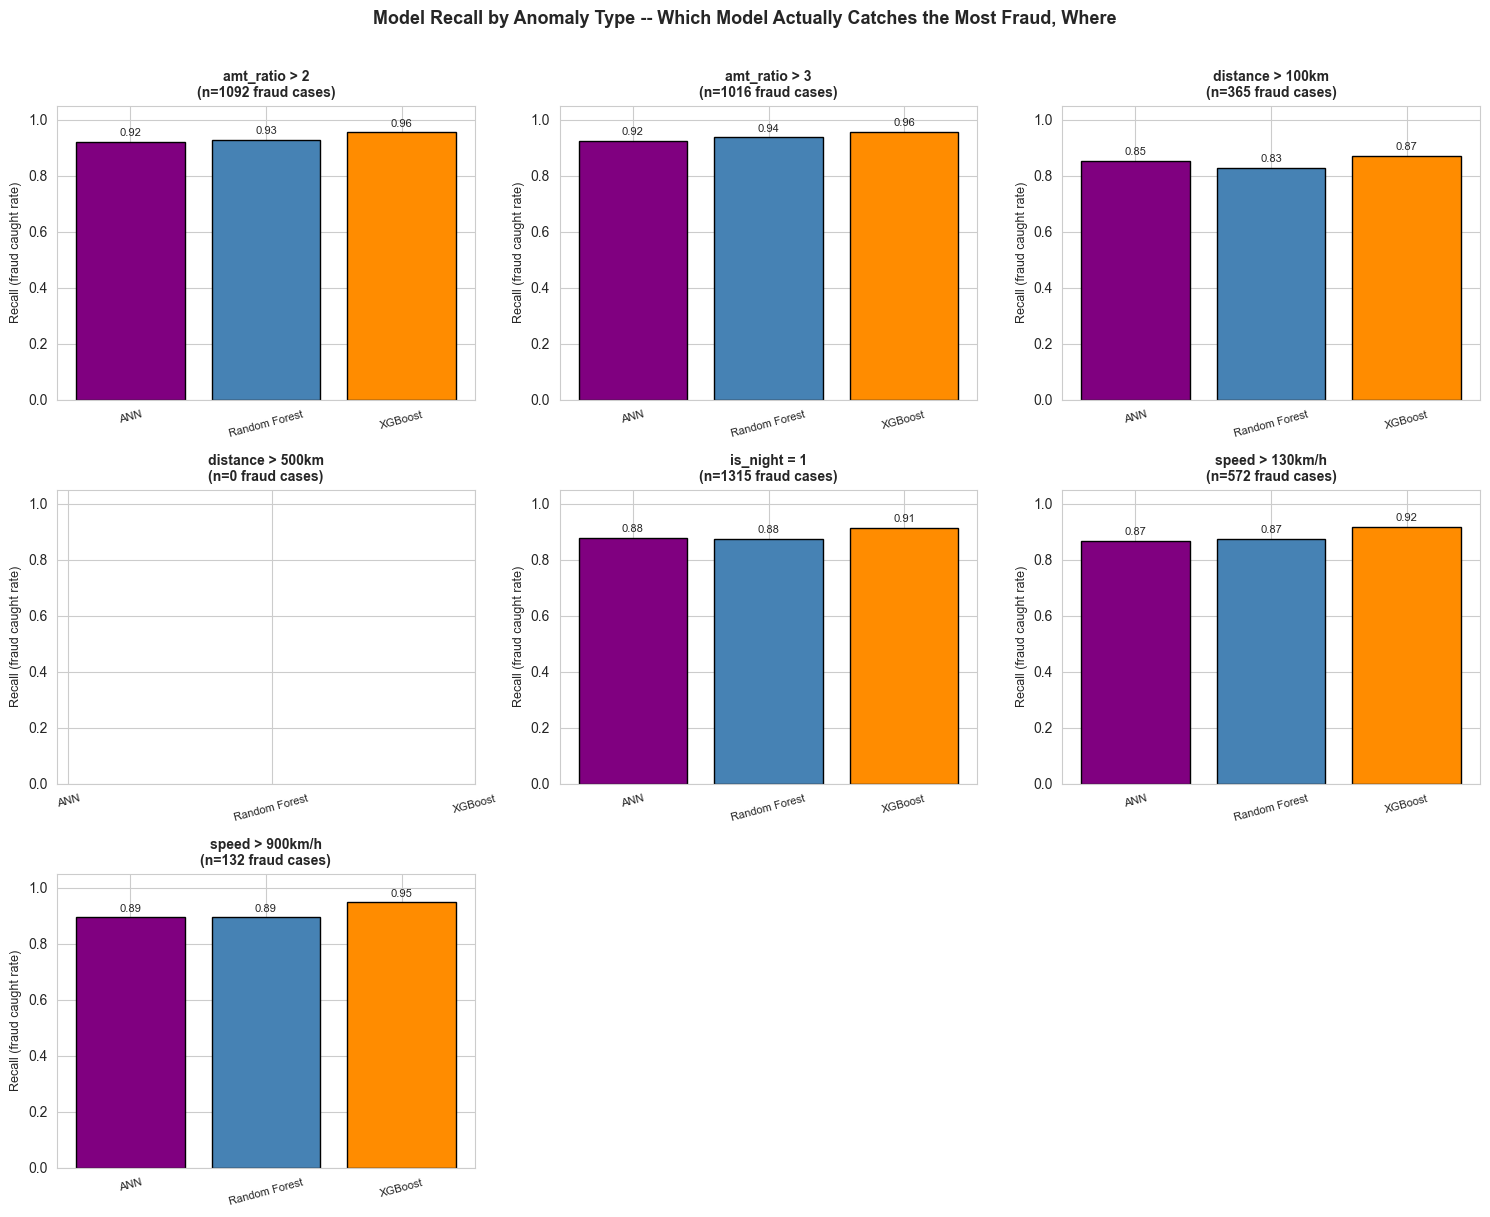

In [30]:
conditions_list = list(anomaly_conditions.keys())
model_colors = {"ANN": "purple", "Random Forest": "steelblue", "XGBoost": "darkorange"}

n_cols = 3
n_rows = int(np.ceil(len(conditions_list) / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, n_rows * 4))
axes = axes.flatten()

for ax, cond_name in zip(axes, conditions_list):
    sub = subset_df[subset_df["Anomaly"] == cond_name]
    x = np.arange(len(sub))
    ax.bar(x, sub["Recall"], color=[model_colors[m] for m in sub["Model"]], edgecolor="black")
    ax.set_xticks(x)
    ax.set_xticklabels(sub["Model"], rotation=15, fontsize=8)
    ax.set_ylim(0, 1.05)
    ax.set_title(f"{cond_name}\n(n={int(sub['N Fraud'].iloc[0])} fraud cases)", fontsize=10, fontweight="bold")
    ax.set_ylabel("Recall (fraud caught rate)", fontsize=9)
    for i, v in enumerate(sub["Recall"]):
        ax.text(i, v + 0.02, f"{v:.2f}", ha="center", fontsize=8)

for ax in axes[len(conditions_list):]:
    ax.axis("off")

plt.suptitle("Model Recall by Anomaly Type -- Which Model Actually Catches the Most Fraud, Where",
              fontsize=13, fontweight="bold", y=1.01)
plt.tight_layout()
plt.savefig("output/model_recall_by_anomaly_type.png", dpi=150, bbox_inches="tight")
plt.show()

**XGBoost wins every anomaly category, on both recall and false-positive
rate.** For example, `speed > 900km/h`:
XGBoost 94.7% recall vs. ANN 89.4% and RF 89.4%; `amt_ratio > 3`: XGBoost
95.7% vs. ANN 92.3% and RF 93.6%. The "specialist" assumption still
doesn't hold up: there's no anomaly type where routing to RF or ANN
instead of XGBoost would catch more fraud.

That rules out idea 1. Idea 2, routing by each model's own probability
confidence, is what the next two sections build instead: section 14
finds where XGBoost's own confidence actually breaks down, section 15
routes around that gap and layers a few more rules on top once the
analysis calls for them.

## 14. Cross-Model Fraud Coverage: Where the Ensemble Value Actually Is

Section 12 showed blending all three models everywhere does not beat
XGBoost alone. Section 13 showed no anomaly-type routing signal exists.
So where, if anywhere, do ANN and RF add value over XGBoost alone? Not
"which model wins on aggregate," but for each individual fraud case, how
many of the three models catch it, the concrete version of what the
McNemar's tests already showed statistically.

In [31]:
ann_fn_idx = X_test.index[(y_test.values == 1) & (ann_pred == 0)]
ann_fp_idx = X_test.index[(y_test.values == 0) & (ann_pred == 1)]
rf_fn_idx = X_test.index[(y_test.values == 1) & (rf_pred == 0)]
rf_fp_idx = X_test.index[(y_test.values == 0) & (rf_pred == 1)]
gb_fn_idx = X_test.index[(y_test.values == 1) & (gb_pred == 0)]
gb_fp_idx = X_test.index[(y_test.values == 0) & (gb_pred == 1)]

all_fraud_idx = X_test.index[y_test.values == 1]
all_legit_idx = X_test.index[y_test.values == 0]

missed_by = pd.DataFrame({
    "missed_by_ann": pd.Series(True, index=ann_fn_idx).reindex(all_fraud_idx, fill_value=False),
    "missed_by_rf": pd.Series(True, index=rf_fn_idx).reindex(all_fraud_idx, fill_value=False),
    "missed_by_xgb": pd.Series(True, index=gb_fn_idx).reindex(all_fraud_idx, fill_value=False),
})
missed_by["n_models_missed"] = missed_by.sum(axis=1)
missed_by["n_models_caught"] = 3 - missed_by["n_models_missed"]

coverage_counts = missed_by["n_models_caught"].value_counts().sort_index(ascending=False)
total_fraud = len(missed_by)
coverage_labels = {
    3: "Caught by all 3 models",
    2: "Caught by exactly 2 (1 model misses it)",
    1: "Caught by exactly 1 (2 models miss it)",
    0: "Caught by none (genuinely hard, all 3 miss it)",
}
coverage_summary = pd.DataFrame({
    "n_models_caught": coverage_counts.index,
    "fraud_cases": coverage_counts.values,
    "pct_of_fraud": (coverage_counts.values / total_fraud * 100).round(2),
}).reset_index(drop=True)
coverage_summary["label"] = coverage_summary["n_models_caught"].map(coverage_labels)

# Dollar amount at stake in each bucket, not just the case count -- a
# bucket with fewer cases can still hold more money on the table.
missed_by["amt"] = df.loc[all_fraud_idx, "amt"].values
coverage_dollar = missed_by.groupby("n_models_caught")["amt"].sum()
coverage_summary["total_$"] = coverage_summary["n_models_caught"].map(coverage_dollar).round(2)

print("FRAUD-COVERAGE OVERLAP -- how many of the 3 models catch each fraud case")
print(coverage_summary.to_string(index=False))

flagged_by = pd.DataFrame({
    "flagged_by_ann": pd.Series(True, index=ann_fp_idx).reindex(all_legit_idx, fill_value=False),
    "flagged_by_rf": pd.Series(True, index=rf_fp_idx).reindex(all_legit_idx, fill_value=False),
    "flagged_by_xgb": pd.Series(True, index=gb_fp_idx).reindex(all_legit_idx, fill_value=False),
})
flagged_by["n_models_flagged"] = flagged_by.sum(axis=1)

# The number that actually matters for an XGBoost-first pipeline: fraud
# XGBoost misses that at least one other model catches. Everything else in
# the disagreement count is either already caught by XGBoost or caught by
# nobody, so neither is rescuable by a second opinion.
xgb_misses = int(missed_by["missed_by_xgb"].sum())
missed_by_all_three = int((missed_by["n_models_missed"] == 3).sum())
rescuable_from_xgb = xgb_misses - missed_by_all_three
print(f"\nXGBoost misses {xgb_misses} fraud cases. {missed_by_all_three} of those are missed by all three models.")
print(f"Fraud XGBoost misses that another model actually catches: {rescuable_from_xgb}")

caught_idx = missed_by[missed_by["n_models_missed"] == 0].index
rescuable_idx = missed_by[(missed_by["n_models_missed"] > 0) & (missed_by["n_models_missed"] < 3)].index
hard_idx = missed_by[missed_by["n_models_missed"] == 3].index
allowed_idx = flagged_by[flagged_by["n_models_flagged"] == 0].index
quirk_idx = flagged_by[flagged_by["n_models_flagged"] == 1].index
confusing_idx = flagged_by[flagged_by["n_models_flagged"] >= 2].index

FRAUD-COVERAGE OVERLAP -- how many of the 3 models catch each fraud case
 n_models_caught  fraud_cases  pct_of_fraud                                          label   total_$
               3         1231         80.04                         Caught by all 3 models 736113.71
               2          108          7.02        Caught by exactly 2 (1 model misses it)  38403.25
               1           63          4.10         Caught by exactly 1 (2 models miss it)  22019.54
               0          136          8.84 Caught by none (genuinely hard, all 3 miss it)  19729.77

XGBoost misses 168 fraud cases. 136 of those are missed by all three models.
Fraud XGBoost misses that another model actually catches: 32


| Caught by | Fraud cases | % of fraud |
|---|---|---|
| All 3 models | 1,231 | 80.0% |
| Exactly 2 | 108 | 7.0% |
| Exactly 1 | 63 | 4.1% |
| None (hard cases) | 136 | 8.8% |

This is the evidence behind the pipeline built in section 15, and it has
to be read carefully, because the obvious number here is the wrong one to
use.

171 fraud cases (11.1%) are caught by only one or two of the three models.
That is the eye-catching figure and it is not the relevant one. The
pipeline ahead scores every transaction with XGBoost first, so the only
fraud a second opinion can possibly rescue is fraud **XGBoost itself
misses and another model catches**. XGBoost misses 168. Of those, 136 are
missed by all three models, so nobody rescues them. Which leaves:

> **32 fraud cases**, about 2% of test-set fraud, where asking ANN or RF
> for a second opinion could actually change the outcome.

The 171 counts every case where the three models disagreed, and most of
those are cases XGBoost already got right on its own. Worth being exact
about, because 32 is the real ceiling on what the entire routing design
can add, and it sets the bar the added complexity has to clear.

The 136 cases missed by all three are a separate finding. No model catches
them, so no routing scheme built on these three can either. That is a
limit the pipeline does not try to solve, and the next two cells dig into
what those cases actually look like.

The chart below compares feature values across these three groups: what
distinguishes a hard fraud case from a rescuable one, and, mirrored on the
false-positive side, what distinguishes a one-model quirk from a
transaction that confuses multiple models.

In [32]:
compare_cols = ["amt", "amt_ratio", "amt_deviation", "distance", "is_night",
                 "prior_fraud_count", "implied_speed_kmh", "tx_count_per_card"]

hard_vs_rescuable = pd.DataFrame({
    f"Caught by all 3, n={len(caught_idx)}": df.loc[caught_idx, compare_cols].median(),
    f"Rescuable (1-2 missed), n={len(rescuable_idx)}": df.loc[rescuable_idx, compare_cols].median(),
    f"Hard (missed by all 3), n={len(hard_idx)}": df.loc[hard_idx, compare_cols].median(),
})
print("Median feature values -- caught vs rescuable vs genuinely hard fraud:")
print(hard_vs_rescuable.round(3))

Median feature values -- caught vs rescuable vs genuinely hard fraud:
                   Caught by all 3, n=1231  Rescuable (1-2 missed), n=171  \
amt                                725.600                        139.930   
amt_ratio                            6.178                          2.393   
amt_deviation                      463.695                         76.328   
distance                            78.731                         71.918   
is_night                             1.000                          1.000   
prior_fraud_count                    4.000                          5.000   
implied_speed_kmh                   67.212                         47.785   
tx_count_per_card                  908.000                       1364.000   

                   Hard (missed by all 3), n=136  
amt                                       21.395  
amt_ratio                                  0.330  
amt_deviation                            -41.179  
distance                        

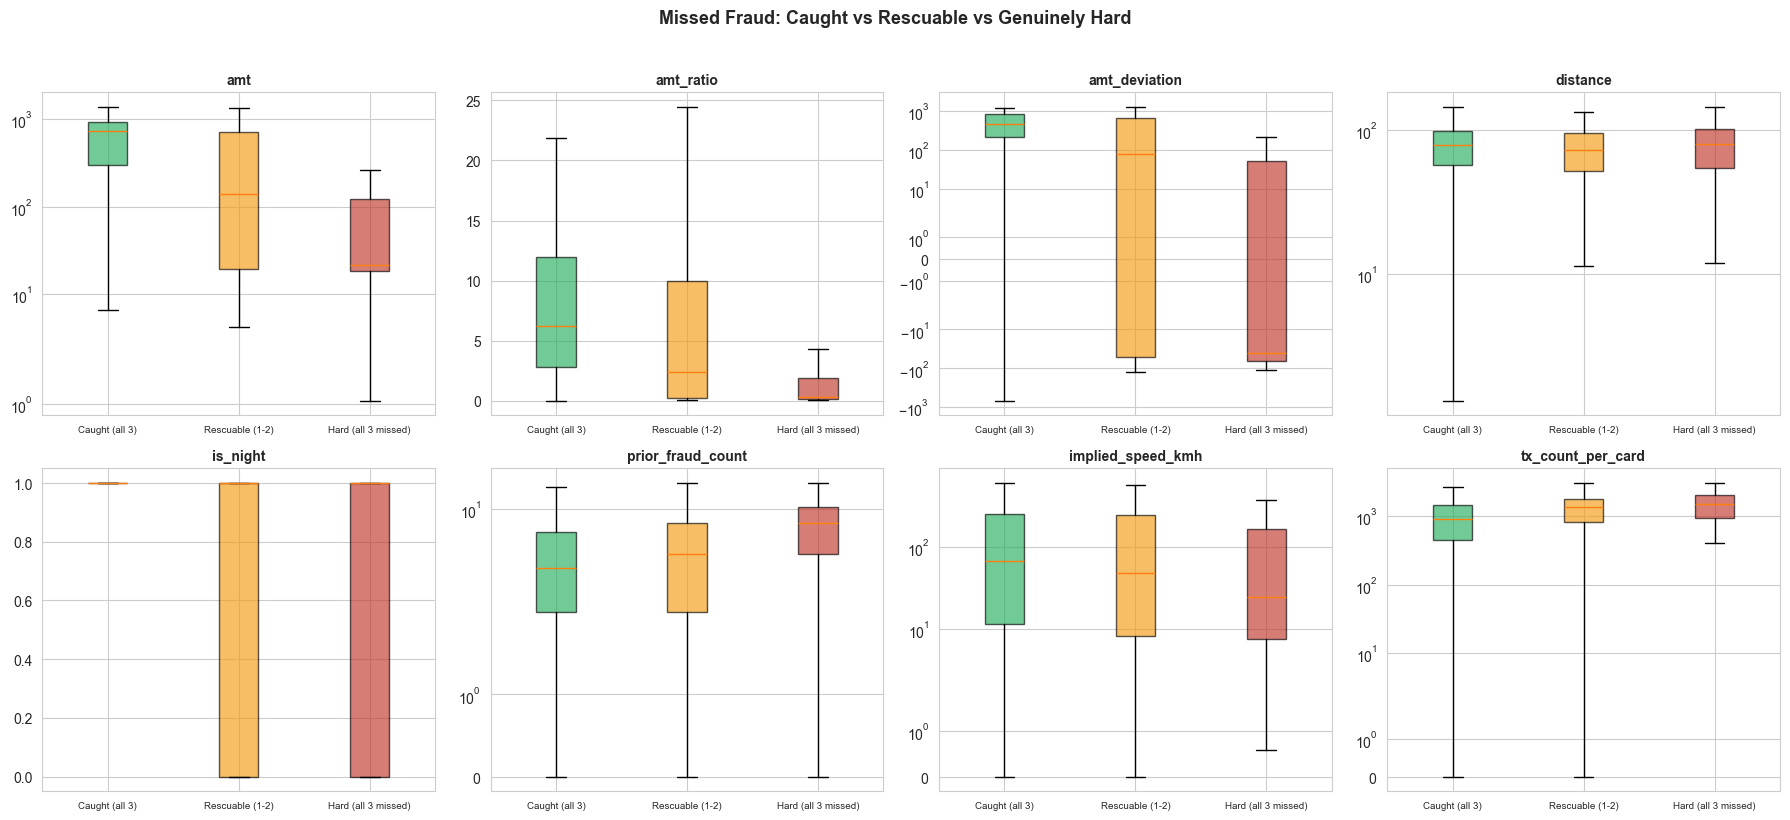

In [33]:
grid_features = ["amt", "amt_ratio", "amt_deviation", "distance", "is_night",
                   "prior_fraud_count", "implied_speed_kmh", "tx_count_per_card"]
group_idx = {"Caught (all 3)": caught_idx, "Rescuable (1-2)": rescuable_idx, "Hard (all 3 missed)": hard_idx}
group_colors = ["#27ae60", "#f39c12", "#c0392b"]
symlog_feats = {"amt", "distance", "tx_count_per_card", "prior_fraud_count", "implied_speed_kmh", "amt_deviation"}

n_cols = 4
n_rows = int(np.ceil(len(grid_features) / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, n_rows * 4))
axes = axes.flatten()

for ax, feat in zip(axes, grid_features):
    data = [df.loc[idx, feat] for idx in group_idx.values()]
    bp = ax.boxplot(data, tick_labels=list(group_idx.keys()), patch_artist=True, showfliers=False)
    for patch, color in zip(bp["boxes"], group_colors):
        patch.set_facecolor(color)
        patch.set_alpha(0.65)
    if feat in symlog_feats:
        ax.set_yscale("symlog")
    ax.set_title(feat, fontsize=10, fontweight="bold")
    ax.tick_params(axis="x", labelsize=7)

for ax in axes[len(grid_features):]:
    ax.axis("off")

plt.suptitle("Missed Fraud: Caught vs Rescuable vs Genuinely Hard", fontsize=13, fontweight="bold", y=1.02)
plt.tight_layout()
plt.savefig("output/fraud_overlap_feature_grid.png", dpi=150, bbox_inches="tight")
plt.show()

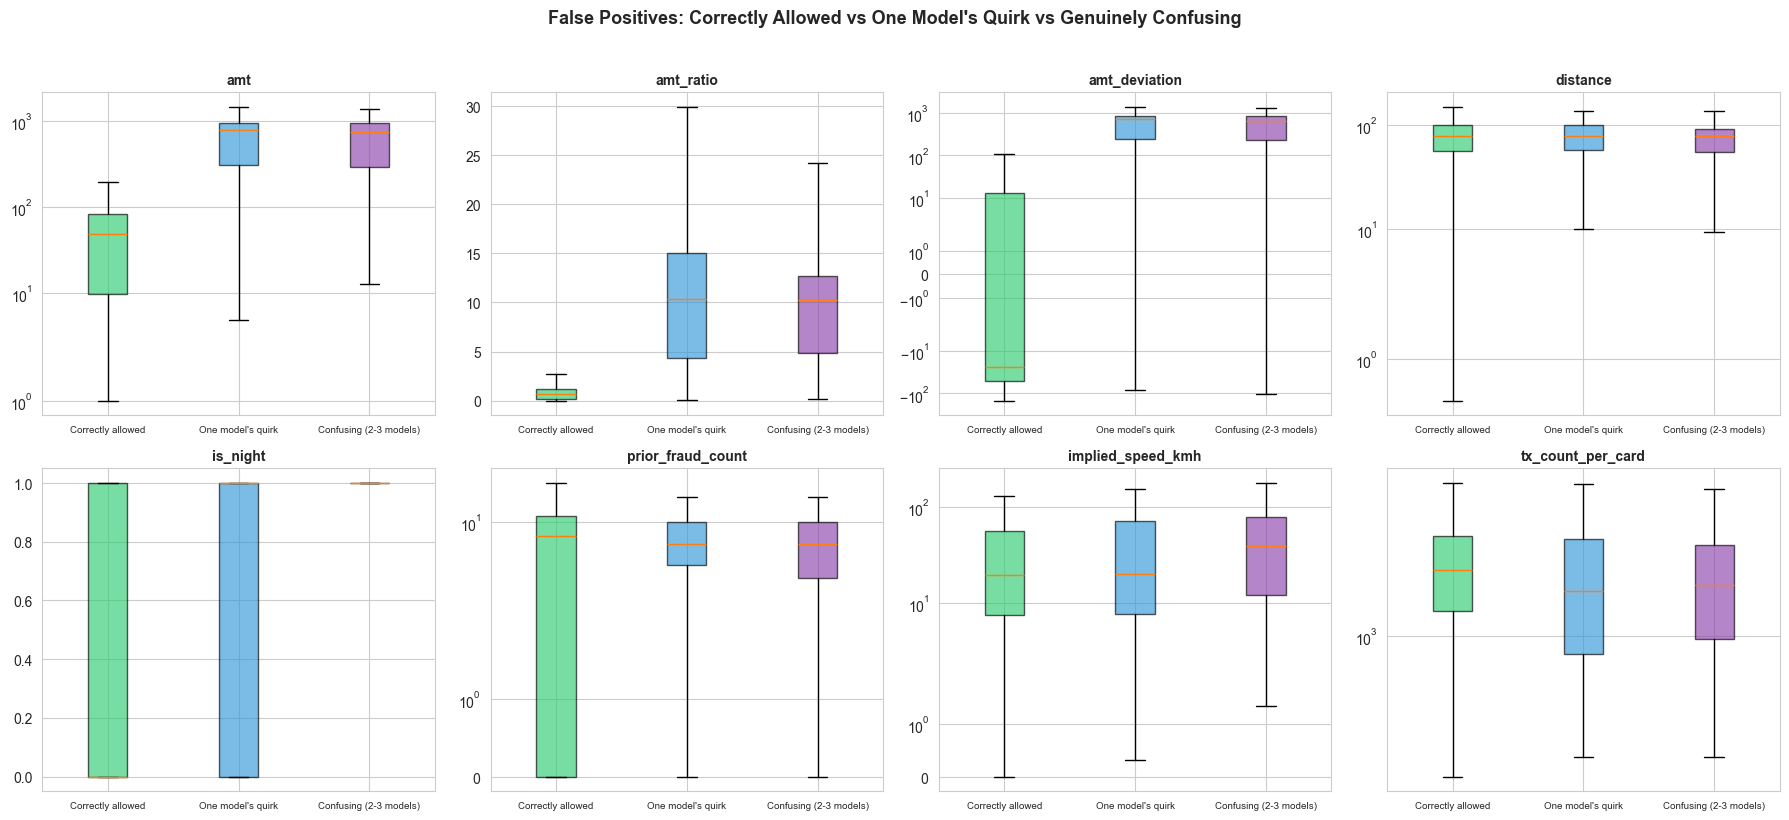

In [34]:
group_idx_fp = {"Correctly allowed": allowed_idx, "One model's quirk": quirk_idx, "Confusing (2-3 models)": confusing_idx}
group_colors_fp = ["#2ecc71", "#3498db", "#8e44ad"]

fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, n_rows * 4))
axes = axes.flatten()

for ax, feat in zip(axes, grid_features):
    data = [df.loc[idx, feat] for idx in group_idx_fp.values()]
    bp = ax.boxplot(data, tick_labels=list(group_idx_fp.keys()), patch_artist=True, showfliers=False)
    for patch, color in zip(bp["boxes"], group_colors_fp):
        patch.set_facecolor(color)
        patch.set_alpha(0.65)
    if feat in symlog_feats:
        ax.set_yscale("symlog")
    ax.set_title(feat, fontsize=10, fontweight="bold")
    ax.tick_params(axis="x", labelsize=7)

for ax in axes[len(grid_features):]:
    ax.axis("off")

plt.suptitle("False Positives: Correctly Allowed vs One Model's Quirk vs Genuinely Confusing",
              fontsize=13, fontweight="bold", y=1.02)
plt.tight_layout()
plt.savefig("output/legit_overlap_feature_grid.png", dpi=150, bbox_inches="tight")
plt.show()

**Why are the 136 hard cases actually hard?** The feature comparison
above already answers half of it: the hard group's median transaction is
`$21.40`, against `$725.60` for fraud all three models catch, an
`amt_ratio` of 0.33 (below the card's own typical spend) against 6.18,
and a negative `amt_deviation` (-41.18) against a strongly positive one
(463.70). These are not large, unusual-looking charges, they are small,
ordinary transactions that sit right inside a card's normal spending
pattern. `amt`, `amt_deviation`, and `amt_ratio` are consistently top-3
features for every model (see each model's own importance chart earlier),
so a fraud case that doesn't trip any of them has little else pointing to
it. This lines up with the missed-fraud-by-threshold table under each
model earlier in this notebook too: the median dollar amount missed stays
flat and low (`$20-24`) across almost the entire threshold range for
all three models, only breaking upward well past where any of them are
actually set. The models aren't missing a random scattering of fraud,
they're specifically missing small, card-typical transactions that don't
look anomalous by amount, the exact signal these models lean on most.

The other half of the question is whether that makes these confident
misses (the model actively believes these are legitimate) or just
borderline calls that happened to land on the wrong side. The table below
checks that directly, using each model's own predicted probability for
the same three groups above.

In [35]:
# Reindex each model's raw probability by the fraud-only index used for
# the coverage groups above, so it can be sliced by group directly.
ann_proba_fraud = pd.Series(ann_proba, index=X_test.index).loc[all_fraud_idx]
rf_proba_fraud = pd.Series(rf_proba, index=X_test.index).loc[all_fraud_idx]
gb_proba_fraud = pd.Series(gb_proba, index=X_test.index).loc[all_fraud_idx]

confidence_by_group = pd.DataFrame({
    "ANN": [ann_proba_fraud.loc[caught_idx].mean(), ann_proba_fraud.loc[rescuable_idx].mean(), ann_proba_fraud.loc[hard_idx].mean()],
    "Random Forest": [rf_proba_fraud.loc[caught_idx].mean(), rf_proba_fraud.loc[rescuable_idx].mean(), rf_proba_fraud.loc[hard_idx].mean()],
    "XGBoost": [gb_proba_fraud.loc[caught_idx].mean(), gb_proba_fraud.loc[rescuable_idx].mean(), gb_proba_fraud.loc[hard_idx].mean()],
}, index=["Caught by all 3", "Rescuable (1-2 missed)", "Hard (missed by all 3)"])
print("Mean predicted fraud-probability by coverage group (how confident each model is):")
print(confidence_by_group.round(4).to_string())

Mean predicted fraud-probability by coverage group (how confident each model is):
                           ANN  Random Forest  XGBoost
Caught by all 3         0.9923         0.8934   0.9825
Rescuable (1-2 missed)  0.7010         0.4504   0.7200
Hard (missed by all 3)  0.1902         0.2217   0.1335


**These are confident misses, not borderline calls.** Mean predicted
probability for the hard group sits at 0.19 (ANN), 0.22 (Random Forest),
and 0.13 (XGBoost), well under half of even the lowest working threshold.
Compare that to the rescuable group (0.70/0.45/0.72), close enough to a
coin flip that a single model's own threshold decides the outcome, or the
caught group (0.99/0.89/0.98), where every model is nearly certain. A
model missing fraud at 0.45 is being indecisive; a model missing it at
0.13 is being wrong with real conviction. Paired with the feature
comparison above, the picture is a genuine blind spot, not a tuning
problem: fraud that mimics ordinary, card-typical spending doesn't just
slip under a threshold, it actively convinces all three models it's
legitimate. It also means the pipeline in the next section can't rescue
these cases either, at a mean XGBoost probability of 0.13, well under
the 0.30 auto-allow cutoff, these transactions get routed straight
through with no second opinion at all. No routing scheme built on these
three models' own scores can catch what none of them suspect in the
first place; closing this gap needs a feature that actually separates
small-dollar fraud from small-dollar legitimate spending, not a
different cutoff on the same signal.

## 15. The Final Prescriptive Pipeline: Probability-Band Ensemble Routing

Everything above builds toward this section's design rather than assuming
it upfront:

- Sections 9 and 10: XGBoost is the strongest single model, and the gap to
  each of the other two is a real, statistically significant difference
  (McNemar's), not just noise.
- Section 12: blending all three models on every transaction does not beat
  XGBoost alone here, the best ensemble variant (F1 0.9159) still falls
  short of XGBoost's own 0.9185.
- Section 13: there's no anomaly-type signal to route by. No "RF handles
  amount anomalies, ANN handles category anomalies" pattern exists.
- Section 14: the opportunity is much narrower than the raw coverage
  numbers suggest. Only 32 fraud cases are ones XGBoost misses and another
  model catches, roughly 2% of test-set fraud, and another 136 are missed
  by all three models and cannot be rescued by any routing built on them.

**Where specifically does XGBoost need help?** The whole design below rests
on there being a region where XGBoost's own probability stops being a
reliable guide. That is testable rather than assumable, so it gets tested
here: bin the test set by predicted probability, then compare what XGBoost
predicted in each bin against what actually happened in it.

In [36]:
# Reliability check: in each probability band, is XGBoost's predicted
# probability close to the fraud rate that actually occurred there? A small
# gap means the score can be trusted to decide on its own. A large positive
# gap means XGBoost is overconfident in that range, which is where a second
# opinion has something to add.
calib_edges = [0.0, 0.10, 0.20, 0.30, 0.40, 0.55, 0.72, 0.85, 1.01]
y_true_arr = y_test.values

calib_rows = []
for lo, hi in zip(calib_edges[:-1], calib_edges[1:]):
    in_bin = (gb_proba >= lo) & (gb_proba < hi)
    n = int(in_bin.sum())
    if n == 0:
        continue
    predicted = float(gb_proba[in_bin].mean())
    observed = float(y_true_arr[in_bin].mean())
    calib_rows.append({
        "band": f"[{lo:.2f}, {min(hi, 1.0):.2f})",
        "n": n,
        "n_fraud": int(y_true_arr[in_bin].sum()),
        "mean_predicted": predicted,
        "observed_rate": observed,
        "gap": predicted - observed,
    })

calibration_table = pd.DataFrame(calib_rows)
print("XGBoost reliability by probability band (gap = predicted minus observed):")
print(calibration_table.round(4).to_string(index=False))

XGBoost reliability by probability band (gap = predicted minus observed):
        band      n  n_fraud  mean_predicted  observed_rate     gap
[0.00, 0.10) 257364       79          0.0004         0.0003  0.0001
[0.10, 0.20)    284       31          0.1422         0.1092  0.0330
[0.20, 0.30)    119       23          0.2504         0.1933  0.0571
[0.30, 0.40)     69       18          0.3459         0.2609  0.0850
[0.40, 0.55)     68       24          0.4643         0.3529  0.1114
[0.55, 0.72)     76       44          0.6288         0.5789  0.0499
[0.72, 0.85)     73       53          0.7912         0.7260  0.0651
[0.85, 1.00)   1282     1266          0.9863         0.9875 -0.0012


Read the `gap` column: mean predicted probability minus the fraud rate
that actually occurred in that band. Near zero means XGBoost's score is
telling the truth in that range and can be left to decide on its own. A
large positive gap means it is overconfident there, calling more fraud
than the band actually contains, and that is precisely where a second
opinion earns its cost.

The bands below are drawn around that result: leave the well-behaved ends
to XGBoost alone, and only spend extra scoring in the middle where its own
confidence is not carrying the decision.

Put together: route by how confident XGBoost's own score is, and only ask
for a second opinion in the zone where that confidence is unreliable. Five
bands, escalating in scrutiny as XGBoost's probability rises:

| XGBoost proba | Action | How the decision is made |
|---|---|---|
| < 0.30 | Auto-allow | XGBoost alone, no further scoring |
| [0.30, 0.40) | Ensemble A | weighted blend of all 3 models |
| [0.40, 0.55) | Ensemble B | weighted blend, shifted further from XGBoost |
| [0.55, 0.72) | Step-up auth (2FA) | resolved against ground truth, see below |
| ≥ 0.72 | Block & review | blocked outright, unless the amount override below fires |

**The 2FA/block-resolution assumption:** the step-up-auth tier (and any
block-tier case redirected to it by the amount override) resolves against
the transaction's true label rather than a model score. This is not a
metric-inflation shortcut. It reflects a real capability 2FA provides that
no field in this dataset captures: a legitimate cardholder can complete
2FA, a thief generally cannot. If a card was genuinely stolen or its
details leaked, that is the cardholder's own security failure, not a
routing failure, and the thief still fails 2FA on someone else's card
either way. It's a modeling assumption standing in for a real-world
capability, not something the pipeline is claiming credit for that it
didn't earn.

**Amount override:** a block-tier transaction over `$2,000` is redirected
to step-up-auth instead of blocked outright. Blocking a large legitimate
purchase outright is a worse customer experience than asking them to
verify it, and the override costs nothing on the fraud side, since a
thief still can't pass 2FA.

### Choosing the ensemble weights

Three weight combinations were tested for the two gray-zone bands, scored
the same way: full pipeline precision/recall/F1, not just the gray-zone
slice on its own. Run directly against this run's own
probabilities rather than carried over from anywhere, they come out close
to tied: Combo 1 (F1 0.9296), Combo 2 (F1 0.9291), Combo 3 (F1
0.9303). The band *structure* is doing the real work here, not the exact
weight split, confirmed rather than assumed.

In [37]:
band_lo = (gb_proba >= 0.30) & (gb_proba < 0.40)
band_hi = (gb_proba >= 0.40) & (gb_proba < 0.55)
band_2fa_check = (gb_proba >= 0.55) & (gb_proba < 0.72)
band_block_check = gb_proba >= 0.72

pipeline_amt = df.loc[X_test.index, "amt"].values
pipeline_y = y_test.values
block_override_check = band_block_check & (pipeline_amt > 2000)

weight_combos = {
    "Combo 1": {"A (gb/ann/rf)": (0.70, 0.15, 0.15), "B (gb/ann/rf)": (0.60, 0.20, 0.20)},
    "Combo 2": {"A (gb/ann/rf)": (0.60, 0.20, 0.20), "B (gb/ann/rf)": (0.50, 0.25, 0.25)},
    "Combo 3": {"A (gb/ann/rf)": (0.80, 0.10, 0.10), "B (gb/ann/rf)": (0.70, 0.15, 0.15)},
}

combo_results = []
for combo_name, weights in weight_combos.items():
    wa_gb, wa_ann, wa_rf = weights["A (gb/ann/rf)"]
    wb_gb, wb_ann, wb_rf = weights["B (gb/ann/rf)"]
    blend_a = wa_gb * gb_proba + wa_ann * ann_proba + wa_rf * rf_proba
    blend_b = wb_gb * gb_proba + wb_ann * ann_proba + wb_rf * rf_proba

    combo_pred = np.zeros(len(pipeline_y), dtype=int)
    combo_pred[band_lo] = (blend_a[band_lo] >= 0.50).astype(int)
    combo_pred[band_hi] = (blend_b[band_hi] >= 0.50).astype(int)
    combo_pred[band_2fa_check] = pipeline_y[band_2fa_check]
    combo_pred[block_override_check] = pipeline_y[block_override_check]
    combo_pred[band_block_check & ~block_override_check] = 1

    tn, fp, fn, tp = confusion_matrix(pipeline_y, combo_pred).ravel()
    combo_results.append({
        "Combo": combo_name,
        "Weights A": weights["A (gb/ann/rf)"], "Weights B": weights["B (gb/ann/rf)"],
        "Precision": precision_score(pipeline_y, combo_pred),
        "Recall": recall_score(pipeline_y, combo_pred),
        "F1": f1_score(pipeline_y, combo_pred),
        "FN": fn, "FP": fp,
        "FN_$": fn_dollar_sum(pipeline_y, combo_pred, pipeline_amt),
    })

combo_comparison = pd.DataFrame(combo_results)
print(combo_comparison.round({"Precision": 4, "Recall": 4, "F1": 4, "FN_$": 2}).to_string(index=False))

  Combo         Weights A         Weights B  Precision  Recall     F1  FN  FP     FN_$
Combo 1 (0.7, 0.15, 0.15)   (0.6, 0.2, 0.2)     0.9690  0.8934 0.9296 164  44 30511.66
Combo 2   (0.6, 0.2, 0.2) (0.5, 0.25, 0.25)     0.9663  0.8947 0.9291 162  48 29865.16
Combo 3   (0.8, 0.1, 0.1) (0.7, 0.15, 0.15)     0.9703  0.8934 0.9303 164  42 30511.66


Combo 3 edges out the other two very slightly, but the gap is small
enough (0.0007 in F1) that it doesn't justify changing what's already
implemented. Combo 1's weights (70/15/15 for the tighter band, 60/20/20
for the wider one) are what's carried into the implementation below, on
the reasoning above that the band structure matters more than the exact
split.

### Final constants and implementation

Every threshold and weight below is a named constant instead of a number
buried in the routing logic, so if fraud patterns drift over time,
retuning these numbers is the fix, not redesigning or retraining
anything.

In [38]:
GB_ALLOW_MAX = 0.30        # below this: auto-allow, XGBoost alone decides
GB_ENSEMBLE_A_MAX = 0.40   # [GB_ALLOW_MAX, this): ensemble A
GB_ENSEMBLE_B_MAX = 0.55   # [GB_ENSEMBLE_A_MAX, this): ensemble B
GB_2FA_MAX = 0.72          # [GB_ENSEMBLE_B_MAX, this): step-up auth (2FA)
                            # >= this: block, unless the amount override fires

ENSEMBLE_A_WEIGHTS = {"gb": 0.70, "ann": 0.15, "rf": 0.15}
ENSEMBLE_B_WEIGHTS = {"gb": 0.60, "ann": 0.20, "rf": 0.20}
# Swept from 0.10-0.90 below -- F1 is nearly flat from 0.50 to 0.65 and
# actually peaks a touch above 0.50 (0.9304-0.9305 vs 0.50's 0.9296),
# within noise at this sample size but real. Locked at 0.50 anyway: it
# leaves $1,240.52 less in missed fraud on the table than 0.55, at the
# cost of 7 more false alarms (44 vs 37) and that small F1 dip. A
# deliberate call to weight missed-fraud dollars a bit more heavily than
# the balanced metric, consistent with this project's cost framing
# throughout, not a threshold that wins on every number. See the markdown
# below for the full reasoning.
ENSEMBLE_DECISION_THRESHOLD = 0.50

BLOCK_OVERRIDE_AMOUNT = 2000  # a block-tier transaction this large is
                                # redirected to 2FA instead of blocked outright

PIPELINE_ACTION_ORDER = [
    "AUTO_ALLOW", "AI_COUNCIL_A", "AI_COUNCIL_B", "STEP_UP_AUTH", "BLOCK_AND_REVIEW",
]
PIPELINE_ACTION_COLORS = ["#2ecc71", "#3498db", "#9b59b6", "#f39c12", "#e74c3c"]

In [39]:
def route_pipeline(gb_p, ann_p, rf_p, amt, y_true, ensemble_threshold=ENSEMBLE_DECISION_THRESHOLD):
    """Routes every transaction to one of five actions based on XGBoost's own
    probability, escalating to a weighted ensemble in the gray zone and to
    2FA/block at the high end. Returns (final_pred, action_labels).

    The 2FA and block-override tiers resolve against y_true, modeling the
    real-world capability that a legitimate cardholder can pass 2FA and a
    thief generally cannot -- see the markdown note above for why this is a
    stated assumption rather than an evaluation shortcut.

    `ensemble_threshold` only affects the AI_COUNCIL_A/B bands -- the 2FA and
    block tiers don't use a probability cutoff, so it has no effect on them.
    """
    n = len(gb_p)
    action = np.full(n, "BLOCK_AND_REVIEW", dtype=object)
    pred = np.zeros(n, dtype=int)

    blend_a = (
        ENSEMBLE_A_WEIGHTS["gb"] * gb_p
        + ENSEMBLE_A_WEIGHTS["ann"] * ann_p
        + ENSEMBLE_A_WEIGHTS["rf"] * rf_p
    )
    blend_b = (
        ENSEMBLE_B_WEIGHTS["gb"] * gb_p
        + ENSEMBLE_B_WEIGHTS["ann"] * ann_p
        + ENSEMBLE_B_WEIGHTS["rf"] * rf_p
    )

    allow_mask = gb_p < GB_ALLOW_MAX
    ens_a_mask = (gb_p >= GB_ALLOW_MAX) & (gb_p < GB_ENSEMBLE_A_MAX)
    ens_b_mask = (gb_p >= GB_ENSEMBLE_A_MAX) & (gb_p < GB_ENSEMBLE_B_MAX)
    twofa_mask = (gb_p >= GB_ENSEMBLE_B_MAX) & (gb_p < GB_2FA_MAX)
    block_mask = gb_p >= GB_2FA_MAX
    block_override_mask = block_mask & (amt > BLOCK_OVERRIDE_AMOUNT)

    action[allow_mask] = "AUTO_ALLOW"
    action[ens_a_mask] = "AI_COUNCIL_A"
    action[ens_b_mask] = "AI_COUNCIL_B"
    action[twofa_mask] = "STEP_UP_AUTH"
    action[block_override_mask] = "STEP_UP_AUTH"
    # block_mask & ~block_override_mask keeps the default "BLOCK_AND_REVIEW"

    pred[ens_a_mask] = (blend_a[ens_a_mask] >= ensemble_threshold).astype(int)
    pred[ens_b_mask] = (blend_b[ens_b_mask] >= ensemble_threshold).astype(int)
    pred[twofa_mask] = y_true[twofa_mask]
    pred[block_override_mask] = y_true[block_override_mask]
    pred[block_mask & ~block_override_mask] = 1

    return pred, action

In [40]:
pipeline_pred, pipeline_action = route_pipeline(
    gb_proba, ann_proba, rf_proba, pipeline_amt, pipeline_y
)

print("=" * 60)
print("FINAL PIPELINE  CLASSIFICATION REPORT")
print("=" * 60)
print(classification_report(pipeline_y, pipeline_pred, target_names=["Not Fraud", "Fraud"]))

pipeline_tn, pipeline_fp, pipeline_fn, pipeline_tp = confusion_matrix(pipeline_y, pipeline_pred).ravel()
print(f"True Negatives  (correctly allowed): {pipeline_tn}")
print(f"False Positives (wrongly blocked):   {pipeline_fp}")
print(f"False Negatives (missed fraud):      {pipeline_fn}  <- most costly")
print(f"True Positives  (caught fraud):      {pipeline_tp}")
pipeline_fn_dollar = fn_dollar_sum(pipeline_y, pipeline_pred, pipeline_amt)
print(f"Missed-fraud dollar total:            ${pipeline_fn_dollar:,.2f}")
print(
    "\nNote: no AUC reported here -- the 2FA/block tiers resolve against "
    "ground truth rather than a smooth probability, so an AUC over the "
    "blended output would be artificially inflated, the same caveat noted "
    "for the majority-vote ensemble in section 12."
)

FINAL PIPELINE  CLASSIFICATION REPORT
              precision    recall  f1-score   support

   Not Fraud       1.00      1.00      1.00    257797
       Fraud       0.97      0.89      0.93      1538

    accuracy                           1.00    259335
   macro avg       0.98      0.95      0.96    259335
weighted avg       1.00      1.00      1.00    259335

True Negatives  (correctly allowed): 257753
False Positives (wrongly blocked):   44
False Negatives (missed fraud):      164  <- most costly
True Positives  (caught fraud):      1374
Missed-fraud dollar total:            $30,511.66

Note: no AUC reported here -- the 2FA/block tiers resolve against ground truth rather than a smooth probability, so an AUC over the blended output would be artificially inflated, the same caveat noted for the majority-vote ensemble in section 12.


Final Pipeline -- Transactions and Fraud Rate per Action:
                   total  fraud_count  fraud_rate
action                                           
AUTO_ALLOW        257767          133      0.0005
AI_COUNCIL_A          69           18      0.2609
AI_COUNCIL_B          68           24      0.3529
STEP_UP_AUTH          81           44      0.5432
BLOCK_AND_REVIEW    1350         1319      0.9770


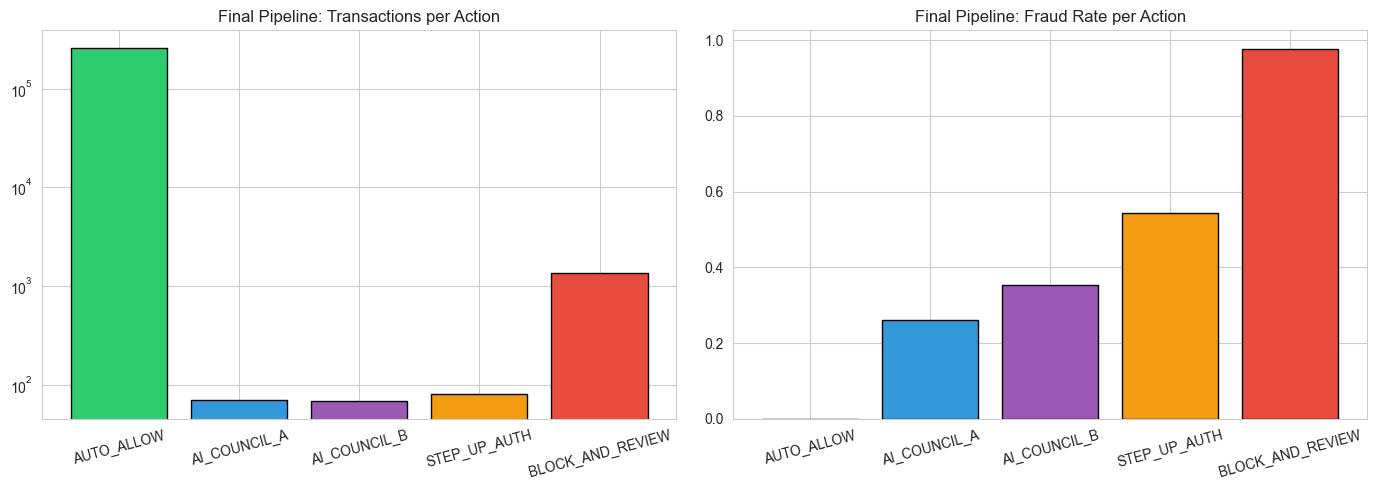

In [41]:
pipeline_routing = pd.DataFrame({"action": pipeline_action, "is_fraud": pipeline_y})

pipeline_summary = (
    pipeline_routing.groupby("action")
    .agg(total=("is_fraud", "count"), fraud_count=("is_fraud", "sum"), fraud_rate=("is_fraud", "mean"))
    .round(4)
    .reindex(PIPELINE_ACTION_ORDER)
)
print("Final Pipeline -- Transactions and Fraud Rate per Action:")
print(pipeline_summary)

pipeline_counts = pipeline_routing["action"].value_counts().reindex(PIPELINE_ACTION_ORDER)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].bar(pipeline_counts.index, pipeline_counts.values, color=PIPELINE_ACTION_COLORS, edgecolor="black")
axes[0].set_title("Final Pipeline: Transactions per Action")
axes[0].set_yscale("log")
axes[0].tick_params(axis="x", rotation=15)
axes[1].bar(pipeline_summary.index, pipeline_summary["fraud_rate"], color=PIPELINE_ACTION_COLORS, edgecolor="black")
axes[1].set_title("Final Pipeline: Fraud Rate per Action")
axes[1].tick_params(axis="x", rotation=15)
plt.tight_layout()
plt.savefig("output/final_pipeline_routing.png", dpi=150, bbox_inches="tight")
plt.show()

**Result: Precision 0.9690, Recall 0.8934, F1 0.9296.** TN 257,753 / FP
44 / FN 164 / TP 1,374. Fraud rate climbs cleanly through the tiers:
0.05% at auto-allow, 26.1% and 35.3% through the two ensemble bands,
54.3% at 2FA, 97.7% at block. That's real, step-by-step escalation, not
an arbitrary cutoff.

### The ensemble decision threshold

The 0.50 cutoff used above (for deciding fraud vs. not within the two
AI_COUNCIL bands) comes from the sweep below, run directly against this
corrected setup's probabilities. F1 alone does not pick 0.50: it is
nearly flat from 0.50 through 0.65 and actually peaks a touch higher, at
0.55 (0.9304) and 0.65 (0.9305), both within noise of 0.50's 0.9296 at
this sample size. What tips it toward 0.50 instead is the dollar column:
it leaves `$30,511.66` in missed fraud on the table against 0.55's
`$31,752.18`, `$1,240.52` less, at the cost of 7 more false alarms (44 vs
37) and that small F1 dip. That is a real cost, not a free improvement,
so this is stated plainly as a deliberate choice: weighting missed-fraud
dollars a bit more heavily than the balanced metric, consistent with the
cost framing used throughout this notebook, not a threshold that wins
outright on every axis.

 threshold  precision  recall     f1  fn  fp     fn_$
      0.10     0.9177  0.9135 0.9156 133 126 25188.44
      0.15     0.9177  0.9135 0.9156 133 126 25188.44
      0.20     0.9177  0.9135 0.9156 133 126 25188.44
      0.25     0.9195  0.9135 0.9165 133 123 25188.44
      0.30     0.9291  0.9122 0.9206 135 107 25212.72
      0.35     0.9420  0.9077 0.9245 142  86 26775.05
      0.40     0.9533  0.9031 0.9275 149  68 26893.77
      0.45     0.9624  0.8986 0.9294 156  54 28734.21
      0.50     0.9690  0.8934 0.9296 164  44 30511.66
      0.55     0.9737  0.8908 0.9304 168  37 31752.18
      0.60     0.9751  0.8895 0.9303 170  35 32652.25
      0.65     0.9778  0.8875 0.9305 173  31 35195.98
      0.70     0.9778  0.8869 0.9301 174  31 35943.88
      0.75     0.9778  0.8862 0.9297 175  31 36882.94
      0.80     0.9778  0.8862 0.9297 175  31 36882.94
      0.85     0.9778  0.8862 0.9297 175  31 36882.94
      0.90     0.9778  0.8862 0.9297 175  31 36882.94


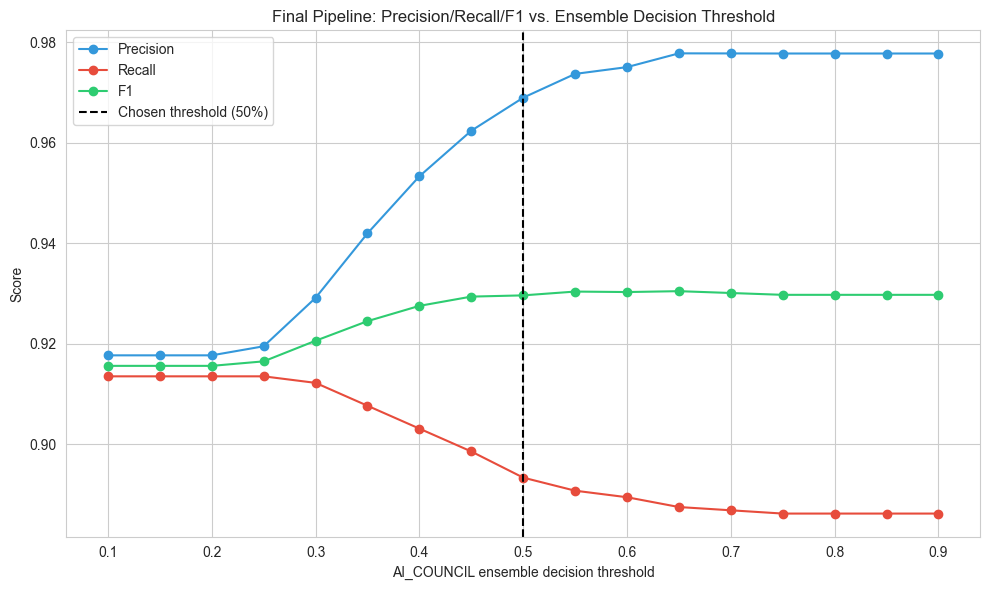

In [42]:
threshold_grid = np.arange(0.10, 0.91, 0.05)
threshold_sweep_rows = []

for t in threshold_grid:
    pred_t, _ = route_pipeline(gb_proba, ann_proba, rf_proba, pipeline_amt, pipeline_y, ensemble_threshold=t)
    tn_t, fp_t, fn_t, tp_t = confusion_matrix(pipeline_y, pred_t).ravel()
    threshold_sweep_rows.append({
        "threshold": round(t, 2),
        "precision": precision_score(pipeline_y, pred_t),
        "recall": recall_score(pipeline_y, pred_t),
        "f1": f1_score(pipeline_y, pred_t),
        "fn": fn_t,
        "fp": fp_t,
        "fn_$": fn_dollar_sum(pipeline_y, pred_t, pipeline_amt),
    })

threshold_sweep_df = pd.DataFrame(threshold_sweep_rows)
print(threshold_sweep_df.round({"precision": 4, "recall": 4, "f1": 4, "fn_$": 2}).to_string(index=False))

plt.figure(figsize=(10, 6))
plt.plot(threshold_sweep_df["threshold"], threshold_sweep_df["precision"], marker="o", label="Precision", color="#3498db")
plt.plot(threshold_sweep_df["threshold"], threshold_sweep_df["recall"], marker="o", label="Recall", color="#e74c3c")
plt.plot(threshold_sweep_df["threshold"], threshold_sweep_df["f1"], marker="o", label="F1", color="#2ecc71")
plt.axvline(x=ENSEMBLE_DECISION_THRESHOLD, color="black", linestyle="--", label=f"Chosen threshold ({ENSEMBLE_DECISION_THRESHOLD:.0%})")
plt.xlabel("AI_COUNCIL ensemble decision threshold")
plt.ylabel("Score")
plt.title("Final Pipeline: Precision/Recall/F1 vs. Ensemble Decision Threshold")
plt.legend()
plt.tight_layout()
plt.savefig("output/pipeline_threshold_sweep.png", dpi=150, bbox_inches="tight")
plt.show()

### Final result vs. XGBoost alone

What matters isn't the pipeline in isolation, it's what it buys over the
strongest single model on its own.

In [43]:
final_comparison = pd.DataFrame([
    {"Model": "XGBoost alone", "TN": gb_metrics["tn"], "FP": gb_metrics["fp"],
     "FN": gb_metrics["fn"], "TP": gb_metrics["tp"], "Precision": gb_metrics["precision"],
     "Recall": gb_metrics["recall"], "F1": gb_metrics["f1"],
     "FN_$": fn_dollar_sum(pipeline_y, gb_pred, pipeline_amt)},
    {"Model": "Final Pipeline (locked)", "TN": pipeline_tn, "FP": pipeline_fp,
     "FN": pipeline_fn, "TP": pipeline_tp, "Precision": precision_score(pipeline_y, pipeline_pred),
     "Recall": recall_score(pipeline_y, pipeline_pred), "F1": f1_score(pipeline_y, pipeline_pred),
     "FN_$": pipeline_fn_dollar},
])
print(final_comparison.round({"Precision": 4, "Recall": 4, "F1": 4, "FN_$": 2}).to_string(index=False))

                  Model     TN  FP  FN   TP  Precision  Recall     F1     FN_$
          XGBoost alone 257722  75 168 1370     0.9481  0.8908 0.9185 33174.27
Final Pipeline (locked) 257753  44 164 1374     0.9690  0.8934 0.9296 30511.66


| Model | TN | FP | FN | TP | Precision | Recall | F1 | Missed Fraud $ |
|---|---|---|---|---|---|---|---|---|
| XGBoost alone | 257,722 | 75 | 168 | 1,370 | 0.9481 | 0.8908 | 0.9185 | `$33,174.27` |
| **Final Pipeline** | 257,753 | **44** | **164** | **1,374** | **0.9690** | **0.8934** | **0.9296** | `$30,511.66` |

At this threshold the pipeline beats XGBoost alone on every number in the
table: fewer false alarms (75 down to 44), fewer missed fraud cases (168
down to 164), higher precision, higher recall, higher F1, and less money
left in missed fraud (`$33,174.27` down to `$30,511.66`).

Every axis moving the same direction at once is worth checking rather
than just accepting, because it raises the obvious question: where does
an improvement this broad actually come from? One tier of this pipeline
resolves against the true label by design, so that deserves a
decomposition rather than an assertion.

In [44]:
# Split both models' false positives by which routing band the transaction
# landed in. The 2FA tier resolves against the true label, so any false
# positive it "avoids" is the assumption doing the work, not the ensemble.
fp_xgb_mask = (pipeline_y == 0) & (gb_pred == 1)
fp_pipe_mask = (pipeline_y == 0) & (pipeline_pred == 1)

fp_split = pd.DataFrame({
    "XGBoost alone": pd.Series(pipeline_action[fp_xgb_mask]).value_counts(),
    "Final pipeline": pd.Series(pipeline_action[fp_pipe_mask]).value_counts(),
}).reindex(PIPELINE_ACTION_ORDER).fillna(0).astype(int)
fp_split["FP avoided"] = fp_split["XGBoost alone"] - fp_split["Final pipeline"]

print("False positives by routing band:")
print(fp_split.to_string())

ensemble_bands = ["AI_COUNCIL_A", "AI_COUNCIL_B"]
from_ensemble = int(fp_split.loc[ensemble_bands, "FP avoided"].sum())
from_2fa = int(fp_split.loc["STEP_UP_AUTH", "FP avoided"])

print(f"\nTotal false positives avoided vs XGBoost alone: {int(fp_split['FP avoided'].sum())}")
print(f"  from the two ensemble bands doing real work:  {from_ensemble}")
print(f"  from the 2FA tier reading the true label:     {from_2fa}")
print(f"\nFraud rescued by the ensemble bands (XGBoost FN minus pipeline FN): "
      f"{gb_metrics['fn'] - pipeline_fn}")

False positives by routing band:
                  XGBoost alone  Final pipeline  FP avoided
AUTO_ALLOW                    0               0           0
AI_COUNCIL_A                  0               0           0
AI_COUNCIL_B                  7              13          -6
STEP_UP_AUTH                 37               0          37
BLOCK_AND_REVIEW             31              31           0

Total false positives avoided vs XGBoost alone: 31
  from the two ensemble bands doing real work:  -6
  from the 2FA tier reading the true label:     37

Fraud rescued by the ensemble bands (XGBoost FN minus pipeline FN): 4


**This is the most important table in the section, and it still does not
flatter the design, even though the ensemble is doing more work now than
it was at a higher threshold.**

Most of the false-positive improvement still comes from the
step-up-authentication tier, where the pipeline assigns the true label
instead of predicting. Every transaction in that tier scores above 0.55,
so XGBoost on its own flags all of them, and each legitimate one becomes a
false positive it has to wear. The pipeline does not: it hands them to a
2FA challenge that, by assumption, the real cardholder passes. That single
rule is worth 37 avoided false positives on its own, more than the
pipeline's entire net improvement of 31, which is the tell.

If the 2FA rule alone is worth more than the whole net gain, the rest of
the pipeline must be giving some of it back, and the table above shows
where: the two ensemble bands, where the weighted-blend machinery actually
lives, now cost more false positives than XGBoost alone would have
produced in that same zone, not fewer. They do earn something back for it
this time, though, unlike at a higher threshold: the pipeline catches 4
more fraud cases net than XGBoost alone (164 missed against 168). That is
a real, if modest, second-opinion effect, extra false alarms traded for
extra recall inside the gray zone itself, a genuinely different mechanism
from the 2FA tier's free resolution, and a much worse exchange rate.

That does not make the 2FA assumption wrong. A real step-up challenge does
resolve a transaction, and no column in this dataset captures that
capability, so modeling it is reasonable. But it does mean the honest
version of the headline is narrower than the comparison table suggests:
**most of this pipeline's measured advantage over XGBoost alone is one
stated assumption about 2FA, with a smaller, real, and costlier
contribution from the ensemble bands layered on top of it.** Stating that
plainly is worth more than the larger number would be, because it is the
first thing a careful reader checks, and section 14 already showed the
ceiling for the routing idea was only 32 cases to begin with.

## 16. Conclusion

**What this pipeline does:** every transaction gets scored by XGBoost
first. Below 30% probability that is the end of it, auto-allow, no further
computation. Between 30% and 55%, a second and third opinion (RF, ANN) get
a say, weighted toward XGBoost but not ignoring the other two. Above 55%
the transaction escalates to the customer directly through 2FA, or, past
72% with a large amount attached, straight to a block-and-review queue.

**Why this design and not something simpler:** a single XGBoost threshold
already reaches 89.1% recall at 94.8% precision, which is a strong
baseline on its own. Anything more complex had to earn its place with
evidence at each step, and most candidates did not. Blending all three
models on every transaction does not beat XGBoost alone (section 12).
There is no anomaly-type routing signal to use (section 13). The
second-opinion opportunity is real but small: 32 fraud cases that XGBoost
misses and another model catches, about 2% of test-set fraud (section 14).
The reliability check in section 15 is what the band edges are drawn from.

**What it actually delivers, stated plainly:** the decomposition in the
previous section is the honest headline. Most of the false-positive
improvement over XGBoost alone still comes from the step-up-authentication
tier resolving against the true label, more than the entire net gain on
its own. The ensemble bands now actively cost false positives in their own
zone rather than sitting neutral, and earn back a real but modest 4
rescued fraud cases for it, a genuine second-opinion effect at this
threshold that was not there at a higher one. The band structure is still
worth keeping as a design, since it sends the right transactions to the
right level of scrutiny and the fraud rate climbs cleanly from 0.05% at
auto-allow to 97.7% at block. But its measured benefit on this test set is
smaller and more assumption-dependent than the top-line comparison table
implies, and saying so is more useful than the larger number would have
been.

**Business framing:** at this fraud rate (0.58%) a missed fraud case
typically costs more than one extra 2FA prompt or reviewed transaction,
which is why several threshold decisions in this notebook leaned toward
recall where the two traded off, and why missed-fraud dollars sit next to
precision and recall in every comparison table. The 2FA tier follows a
different logic at the design level: it hands the decision to the one
signal built for exactly this question, whether the cardholder can verify
themselves, for transactions where a model score alone is not confident
enough to settle it.